# Galería de visualización — Fashion Demand ML

Guía ejecutable para diseñar gráficos **elegantes, legibles y rigurosos** en los informes PDRL y MLLB. Usa datos sintéticos reproducibles inspirados en un panel `article-week`, por lo que no necesita los ficheros privados de H&M.

**Principios:** una pregunta por figura · títulos que comuniquen el hallazgo · unidades explícitas · color con significado · comparación sobre una base común · incertidumbre visible · fuente y notas metodológicas cuando proceda · fechas en formato español (`dd/mm/aaaa` o `mm/aaaa`).

> Ejecuta las celdas en orden. Las funciones `finish_plot` y `save_figure` son reutilizables en los notebooks del proyecto.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.ticker import FuncFormatter, PercentFormatter
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import gaussian_kde
from sklearn.calibration import calibration_curve
from sklearn.metrics import (ConfusionMatrixDisplay, auc, confusion_matrix,
                             precision_recall_curve, roc_curve, silhouette_samples)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
rng = np.random.default_rng(SEED)

# Paleta sobria, con contraste razonable y un único color de énfasis.
INK, MUTED, GRID, PAPER = '#17212B', '#667085', '#DDE3EA', '#FAFBFC'
BLUE, TEAL, CORAL, GOLD, VIOLET = '#2F6BFF', '#16A085', '#E76F51', '#E9A23B', '#7357C8'
PALETTE = [BLUE, TEAL, CORAL, GOLD, VIOLET, '#4C956C', '#C8553D', '#5B8EAD']

sns.set_theme(style='whitegrid', context='notebook', palette=PALETTE)
mpl.rcParams.update({
    'figure.figsize': (11, 6), 'figure.dpi': 120, 'savefig.dpi': 240,
    'figure.facecolor': PAPER, 'axes.facecolor': PAPER, 'savefig.facecolor': PAPER,
    # Arial usa archivos regular/bold separados, evitando que Matplotlib simule el peso.
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 10, 'font.weight': 'normal',
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 18,
    'axes.labelsize': 10, 'axes.labelweight': 'bold', 'axes.labelcolor': MUTED, 'axes.edgecolor': GRID,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': .7,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'legend.frameon': True, 'legend.fancybox': True, 'legend.framealpha': .96,
    'legend.facecolor': '#FFFFFF', 'legend.edgecolor': GRID,
    'legend.borderpad': .65, 'legend.labelspacing': .55, 'legend.columnspacing': 1.25,
    'legend.fontsize': 9, 'lines.linewidth': 2.2,
})

def finish_plot(ax, title, subtitle=None, xlabel=None, ylabel=None, source='Datos sintéticos · semilla 42'):
    # Un único título centrado; la explicación metodológica vive en el texto del notebook.
    ax.set_title(title, loc='center', color=INK, fontsize=14, fontweight='bold', pad=18, wrap=True)
    ax.set(xlabel=xlabel, ylabel=ylabel)
    ax.xaxis.label.set_fontweight('bold')
    ax.yaxis.label.set_fontweight('bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', visible=False)
    if source:
        ax.text(0, -0.20, source, transform=ax.transAxes, color=MUTED, fontsize=8, va='top', clip_on=False)
    return ax

def format_date_axis(ax, detail='month', interval=2):
    # Convención española: día/mes/año; si no hay día, mes/año.
    if detail == 'day':
        ax.xaxis.set_major_locator(mdates.DayLocator(interval=interval))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m/%Y'))
    else:
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=interval))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
    ax.tick_params(axis='x', rotation=0)
    return ax

def save_figure(fig, name, directory='../../results/figures'):
    path = Path(directory)
    path.mkdir(parents=True, exist_ok=True)
    fig.savefig(path / f'{name}.png', bbox_inches='tight')
    fig.savefig(path / f'{name}.svg', bbox_inches='tight')

def annotate_bars(ax, fmt='{:.0f}'):
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, padding=3, color=INK, fontsize=8)

print('Entorno visual configurado · semilla:', SEED)

Entorno visual configurado · semilla: 42


## 1. Datos de demostración

Generamos ventas semanales, catálogo, predicciones y métricas de modelos. Las relaciones están construidas para que cada visualización tenga una historia coherente.

In [2]:
weeks = pd.date_range('2023-01-02', periods=78, freq='W-MON')
categories = ['Vestidos', 'Tops', 'Pantalones', 'Punto', 'Accesorios']
regions = ['Norte', 'Centro', 'Mediterráneo', 'Sur']
rows = []
for i, week in enumerate(weeks):
    season = 1 + .22*np.sin(2*np.pi*i/52) + .10*np.cos(2*np.pi*i/13)
    campaign = 1.35 if i in [24, 25, 48, 49, 72] else 1
    for j, cat in enumerate(categories):
        base = [1500, 1250, 1100, 900, 680][j]
        sales = max(100, base*season*campaign*(1 + .004*i) + rng.normal(0, base*.07))
        rows.append((week, cat, sales, sales*rng.uniform(.026, .061), campaign > 1))
weekly = pd.DataFrame(rows, columns=['week', 'category', 'sales', 'revenue', 'campaign'])
weekly['sales'] = weekly['sales'].round().astype(int)
weekly['revenue'] = weekly['revenue'].round(0)

n = 1200
articles = pd.DataFrame({
    'category': rng.choice(categories, n, p=[.22, .26, .21, .18, .13]),
    'price': np.exp(rng.normal(3.25, .42, n)),
    'discount': rng.beta(1.3, 7, n),
    'customers': rng.gamma(3, 18, n).astype(int) + 1,
    'channel': rng.choice(['Online', 'Tienda'], n, p=[.57, .43]),
})
cat_effect = articles['category'].map(dict(zip(categories, [18, 11, 14, 7, 4]))).to_numpy()
articles['demand'] = np.maximum(0, 12 + cat_effect - .42*articles['price'] + 35*articles['discount'] + .5*articles['customers'] + rng.normal(0, 12, n)).round()
articles['high_demand'] = (articles['demand'] >= articles['demand'].quantile(.75)).astype(int)
articles['predicted'] = np.maximum(0, articles['demand'] + rng.normal(0, 10 + .10*articles['demand'], n))
score = (articles['demand'] - articles['demand'].mean()) / articles['demand'].std() + rng.normal(0, .85, n)
articles['probability'] = 1 / (1 + np.exp(-score))

model_metrics = pd.DataFrame({
    'model': ['Naive estacional', 'Elastic Net', 'Random Forest', 'XGBoost'],
    'MAE': [22.8, 18.4, 14.9, 13.7], 'RMSE': [34.1, 28.3, 23.8, 22.5],
    'F1': [.58, .66, .73, .76], 'train_s': [.1, .8, 18.0, 31.0]
})
weekly.head(3)

,week,category,sales,revenue,campaign
0,2023-01-02,Vestidos,1682,70.0,False
1,2023-01-02,Tops,1441,73.0,False
2,2023-01-02,Pantalones,1060,64.0,False


## 2. Evolución temporal

Línea para tendencia; banda para incertidumbre; *small multiples* cuando muchas series competirían por atención. Evitar ejes dobles salvo necesidad excepcional.

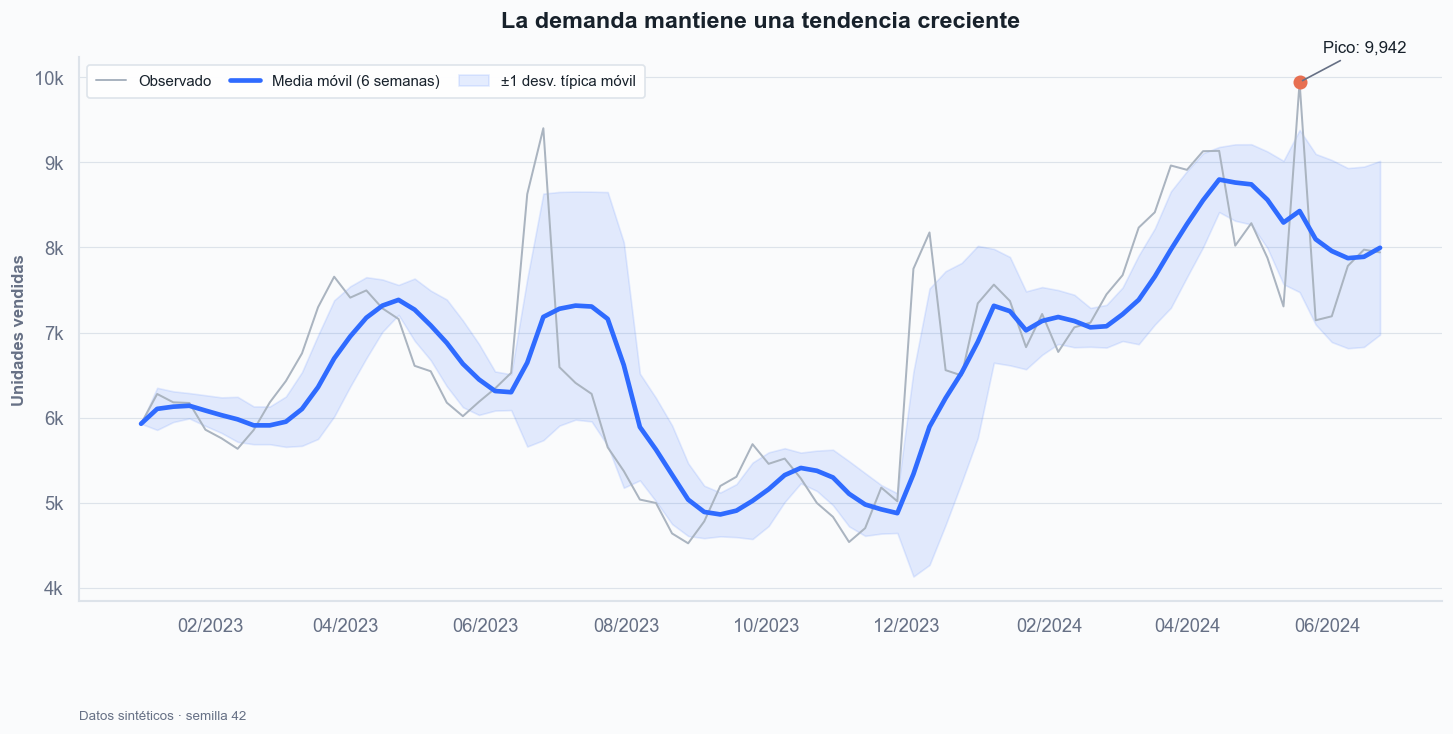

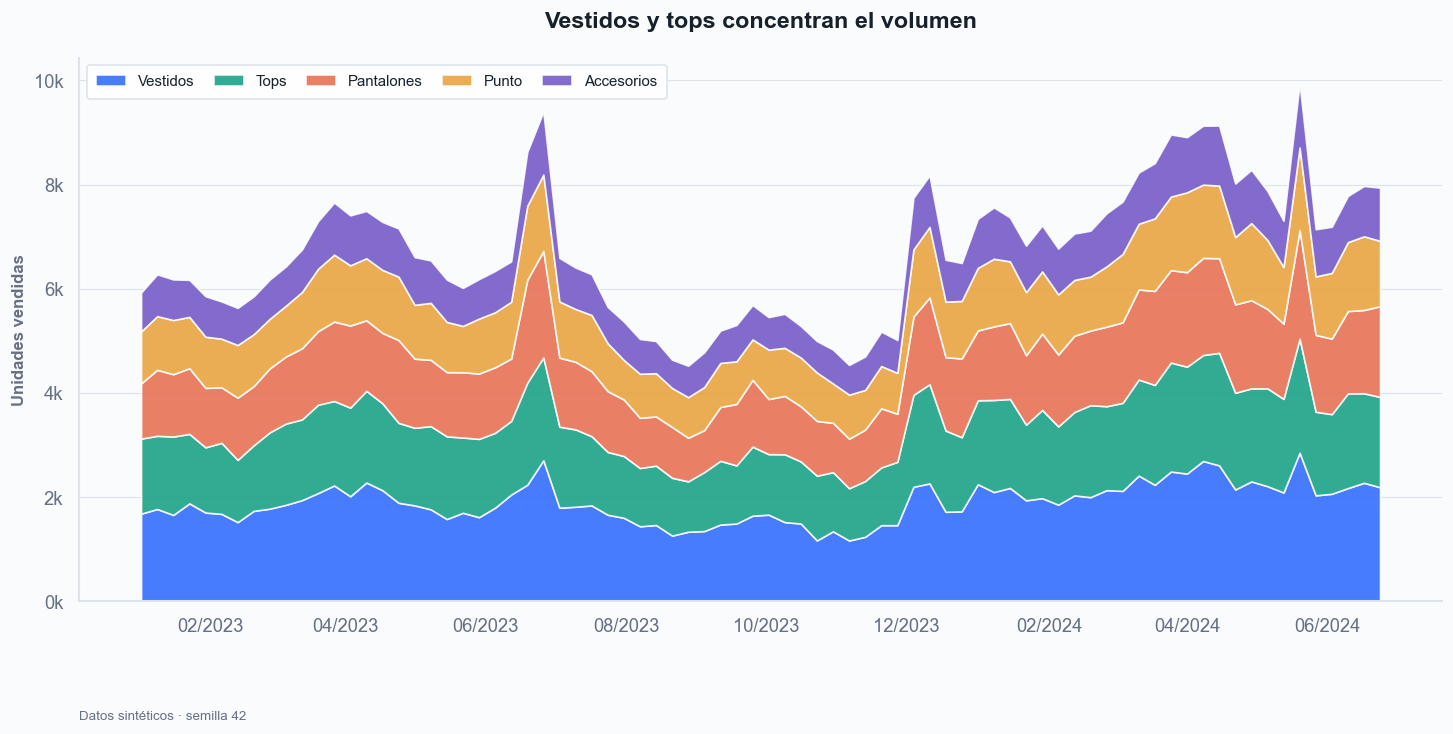

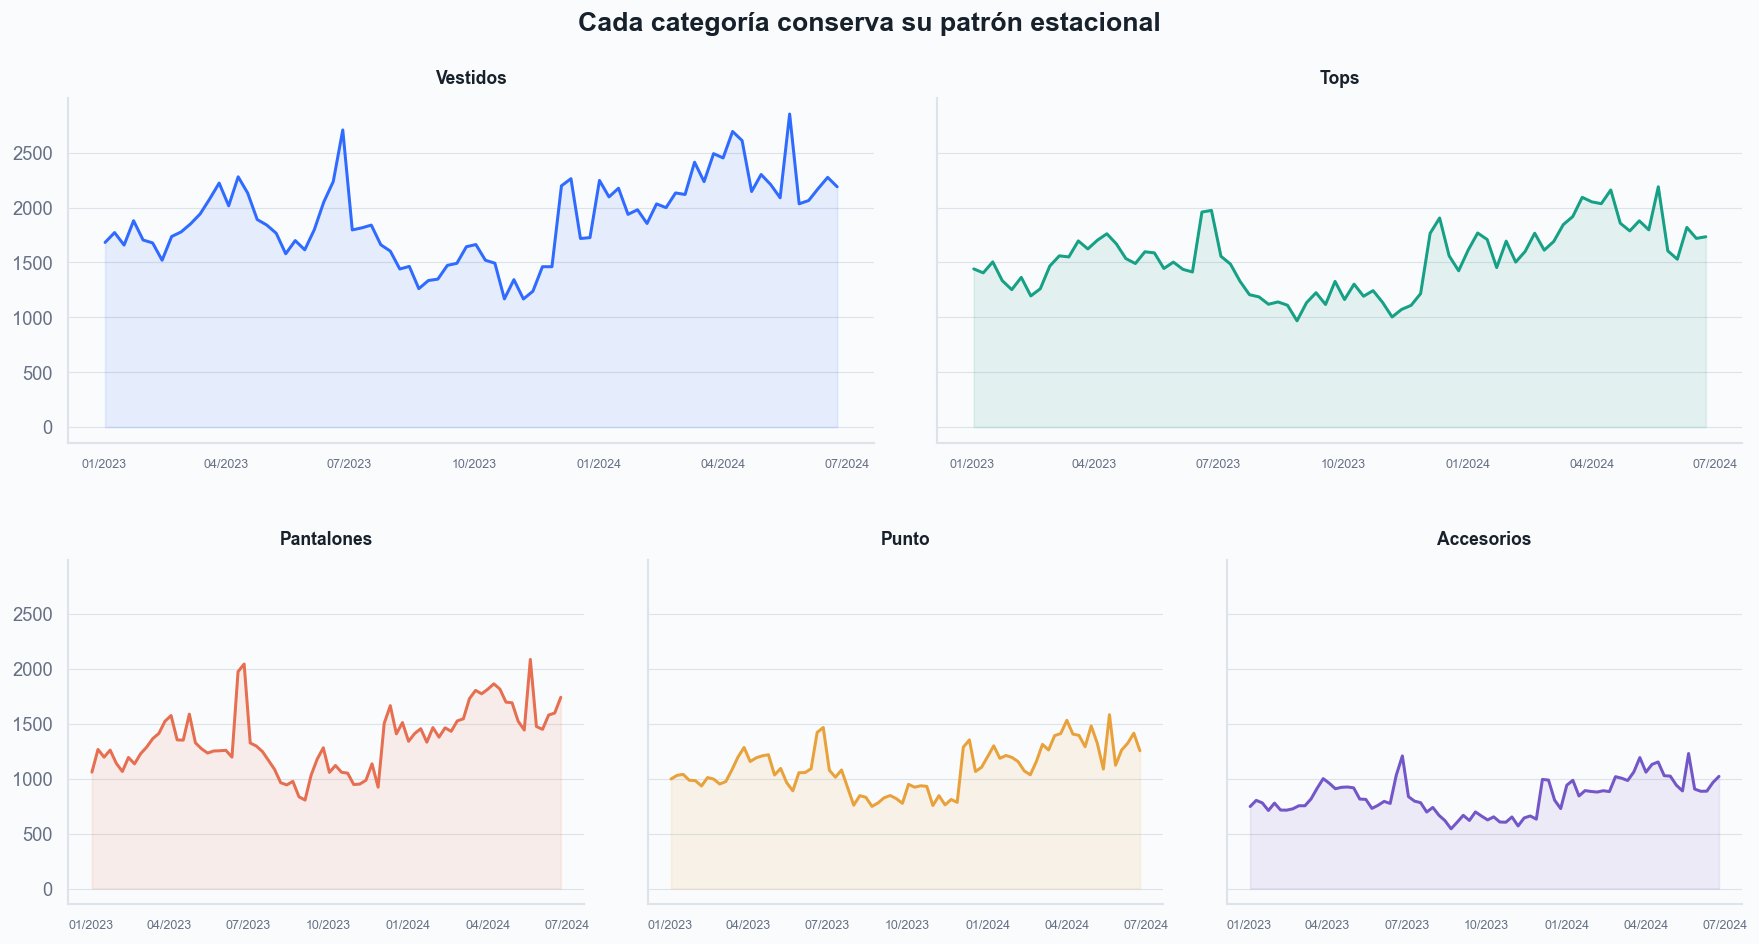

In [3]:
# Línea + media móvil + intervalo de variabilidad
total = weekly.groupby('week', as_index=False)['sales'].sum()
total['rolling'] = total['sales'].rolling(6, min_periods=1).mean()
total['sd'] = total['sales'].rolling(6, min_periods=2).std().fillna(0)
fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
ax.plot(total.week, total.sales, color='#AAB4C0', lw=1.2, label='Observado')
ax.plot(total.week, total['rolling'], color=BLUE, lw=2.8, label='Media móvil (6 semanas)')
ax.fill_between(total.week, total['rolling']-total.sd, total['rolling']+total.sd, color=BLUE, alpha=.12, label='±1 desv. típica móvil')
peak = total.loc[total.sales.idxmax()]
ax.scatter(peak.week, peak.sales, s=55, color=CORAL, zorder=3)
ax.annotate(f'Pico: {peak.sales:,.0f}', (peak.week, peak.sales), xytext=(14, 18), textcoords='offset points', arrowprops={'arrowstyle':'-', 'color':MUTED}, color=INK)
ax.legend(ncol=3, loc='upper left')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
format_date_axis(ax, detail='month', interval=2)
finish_plot(ax, 'La demanda mantiene una tendencia creciente', 'Ventas totales semanales y variabilidad móvil', None, 'Unidades vendidas')
plt.show()

# Área apilada: composición en el tiempo
pivot = weekly.pivot(index='week', columns='category', values='sales')[categories]
fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
ax.stackplot(pivot.index, pivot.T, labels=pivot.columns, colors=PALETTE[:5], alpha=.88)
ax.legend(ncol=5, loc='upper left')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
format_date_axis(ax, detail='month', interval=2)
finish_plot(ax, 'Vestidos y tops concentran el volumen', 'Área apilada: evolución de la composición por categoría', None, 'Unidades vendidas')
plt.show()

# Small multiples: 2 paneles arriba + 3 abajo; ninguna fila queda con un solo panel.
fig = plt.figure(figsize=(15, 8.5))
grid = fig.add_gridspec(2, 6, left=.055, right=.985, bottom=.09, top=.88, hspace=.34, wspace=.28)
slots = [(0, slice(0, 3)), (0, slice(3, 6)),
         (1, slice(0, 2)), (1, slice(2, 4)), (1, slice(4, 6))]
axes = []
for i, (row, cols) in enumerate(slots):
    axes.append(fig.add_subplot(grid[row, cols], sharex=axes[0] if axes else None, sharey=axes[0] if axes else None))

for ax, (cat, data), color in zip(axes, weekly.groupby('category', sort=False), PALETTE):
    ax.plot(data.week, data.sales, color=color, lw=1.8)
    ax.fill_between(data.week, data.sales, color=color, alpha=.10)
    ax.set_title(cat, fontsize=10.5, fontweight='bold', pad=9)
    ax.spines[['top','right']].set_visible(False)
    ax.grid(axis='x', visible=False)
    format_date_axis(ax, detail='month', interval=3)
    ax.tick_params(axis='x', labelsize=7.5, labelbottom=True)

for ax in [axes[1], axes[3], axes[4]]:
    ax.tick_params(labelleft=False)
fig.suptitle('Cada categoría conserva su patrón estacional', y=.965, fontsize=16, fontweight='bold')
plt.show()

## 3. Comparación y composición

Barras ordenadas para magnitudes; barras apiladas al 100 % para composición; *dot/lollipop* para reducir tinta; *slopegraph* para cambios entre dos puntos. La línea base de una barra debe comenzar en cero.

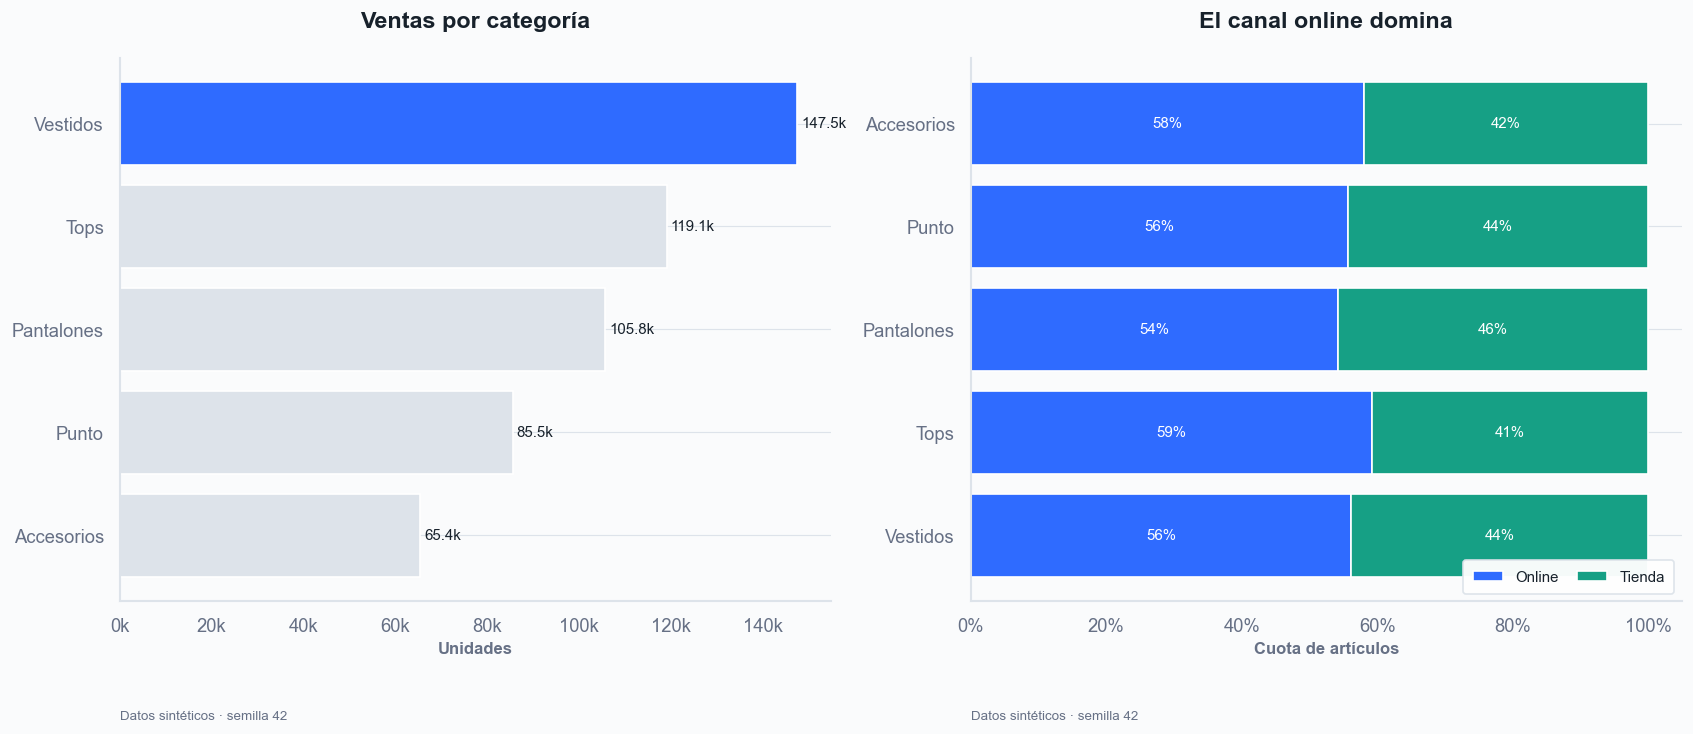

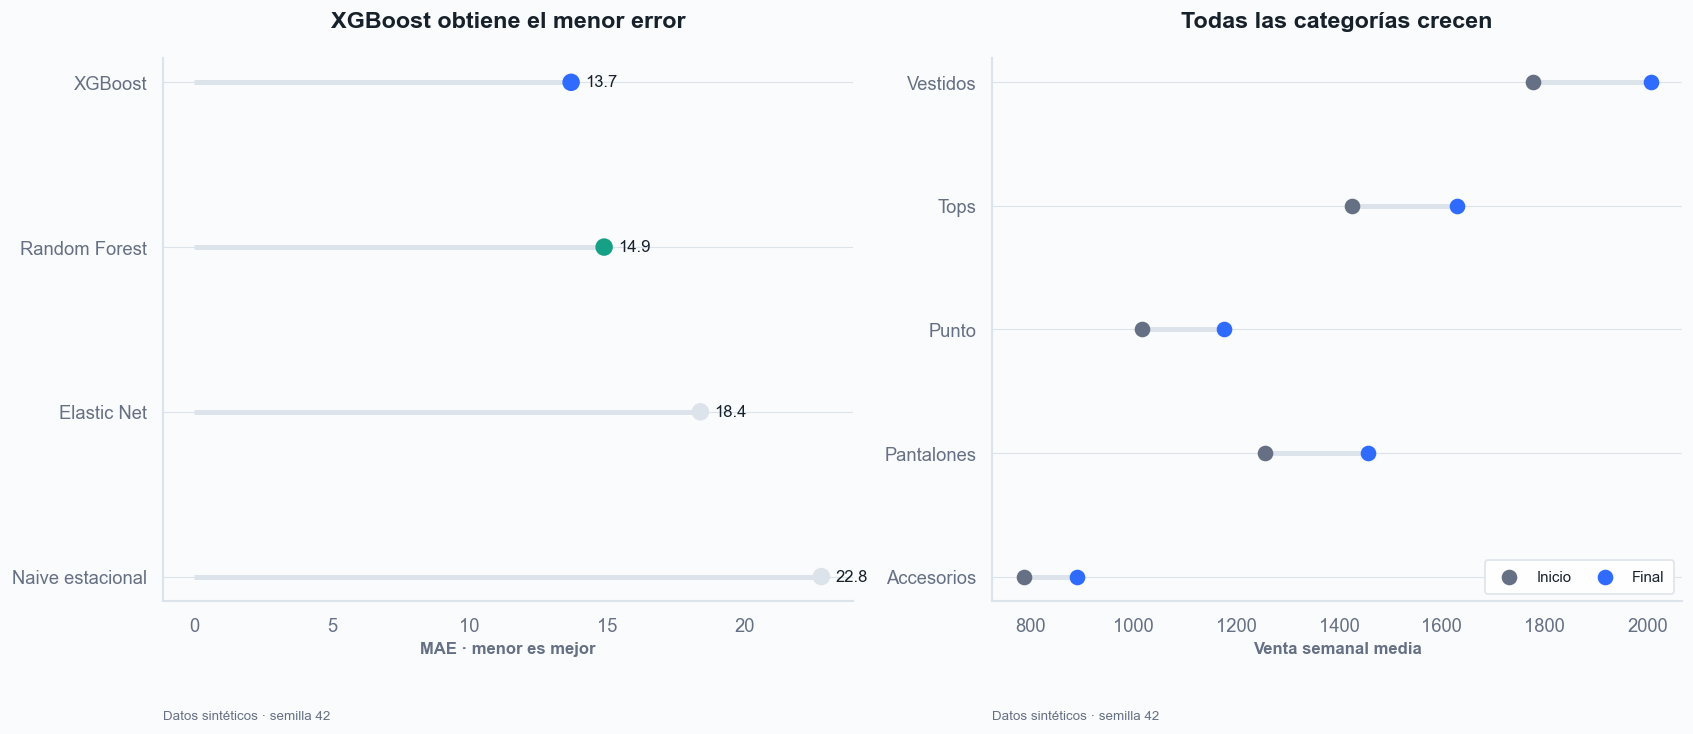

In [4]:
summary = weekly.groupby('category')['sales'].sum().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
colors = [GRID]*(len(summary)-1) + [BLUE]
axes[0].barh(summary.index, summary.values, color=colors)
for y, v in enumerate(summary): axes[0].text(v+800, y, f'{v/1000:.1f}k', va='center', fontsize=9)
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
finish_plot(axes[0], 'Ventas por categoría', 'Barras horizontales ordenadas', 'Unidades', None)

channel = pd.crosstab(articles.category, articles.channel, normalize='index').loc[categories]
left = np.zeros(len(channel))
for col, color in zip(['Online','Tienda'], [BLUE, TEAL]):
    axes[1].barh(channel.index, channel[col], left=left, label=col, color=color)
    for i, (l, v) in enumerate(zip(left, channel[col])):
        axes[1].text(l+v/2, i, f'{v:.0%}', ha='center', va='center', color='white', fontsize=9, fontweight='normal')
    left += channel[col].to_numpy()
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(ncol=2, loc='lower right')
finish_plot(axes[1], 'El canal online domina', 'Barras apiladas al 100 %', 'Cuota de artículos', None)
plt.show()

# Lollipop + comparación directa tipo dumbbell
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
metrics = model_metrics.sort_values('MAE', ascending=False)
axes[0].hlines(metrics.model, 0, metrics.MAE, color=GRID, lw=3)
axes[0].scatter(metrics.MAE, metrics.model, s=90, color=[GRID, GRID, TEAL, BLUE], zorder=3)
for y, v in zip(metrics.model, metrics.MAE): axes[0].text(v+.5, y, f'{v:.1f}', va='center')
finish_plot(axes[0], 'XGBoost obtiene el menor error', 'Lollipop: menos tinta, misma precisión', 'MAE · menor es mejor', None)

period = weekly.assign(period=np.where(weekly.week < weekly.week.min()+pd.Timedelta(weeks=39), 'Inicio', 'Final')).groupby(['category','period']).sales.mean().unstack()
y = np.arange(len(period))
axes[1].hlines(y, period.Inicio, period.Final, color=GRID, lw=3)
axes[1].scatter(period.Inicio, y, color=MUTED, s=70, label='Inicio', zorder=3)
axes[1].scatter(period.Final, y, color=BLUE, s=70, label='Final', zorder=3)
axes[1].set_yticks(y, period.index); axes[1].legend(ncol=2, loc='lower right')
finish_plot(axes[1], 'Todas las categorías crecen', 'Dumbbell: cambio entre dos periodos', 'Venta semanal media', None)
plt.show()

## 4. Distribuciones

Histograma + KDE para forma; ECDF para cuantiles sin depender del ancho de bin; boxplot para resumen robusto; violin + puntos para forma y observaciones. Reportar siempre tamaño muestral y considerar escala logarítmica en colas largas.

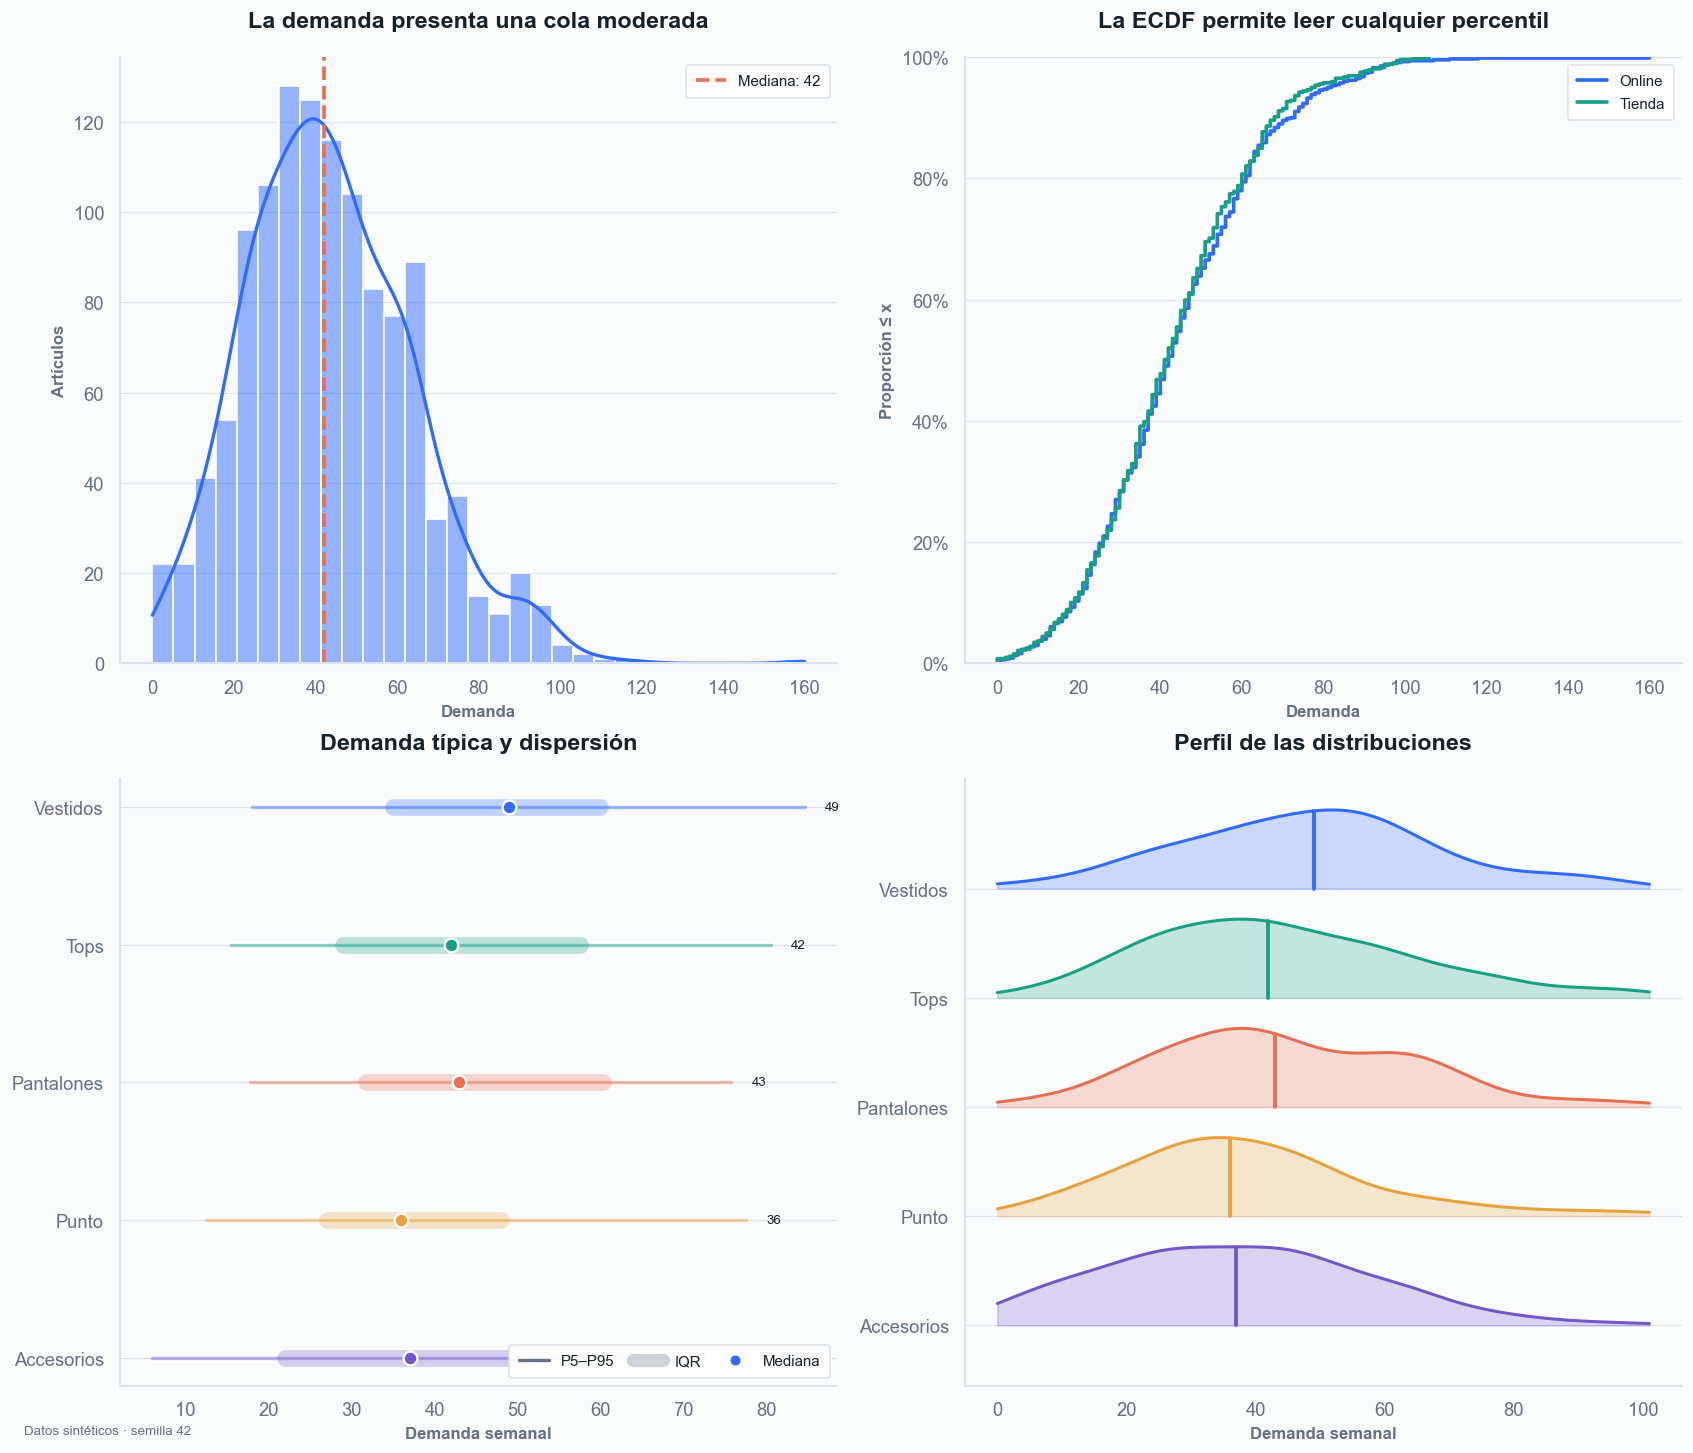

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12), layout='constrained')
sns.histplot(articles, x='demand', bins='fd', kde=True, color=BLUE, ax=axes[0,0], line_kws={'lw':2})
axes[0,0].axvline(articles.demand.median(), color=CORAL, ls='--', label=f'Mediana: {articles.demand.median():.0f}')
axes[0,0].legend(); finish_plot(axes[0,0], 'La demanda presenta una cola moderada', None, 'Demanda', 'Artículos', source=None)

for channel, color in zip(['Online','Tienda'], [BLUE, TEAL]):
    sns.ecdfplot(articles.query('channel == @channel'), x='demand', color=color, label=channel, ax=axes[0,1])
axes[0,1].yaxis.set_major_formatter(PercentFormatter(1)); axes[0,1].legend()
finish_plot(axes[0,1], 'La ECDF permite leer cualquier percentil', None, 'Demanda', 'Proporción ≤ x', source=None)

# Intervalos robustos: P5–P95, IQR y mediana.
quantiles = (articles.groupby('category')['demand']
             .quantile([.05, .25, .50, .75, .95]).unstack()
             .reindex(categories))
ypos = np.arange(len(categories))
for y, (cat, values), color in zip(ypos, quantiles.iterrows(), PALETTE):
    q05, q25, q50, q75, q95 = values
    axes[1,0].plot([q05, q95], [y, y], color=color, lw=2, alpha=.45, solid_capstyle='round')
    axes[1,0].plot([q25, q75], [y, y], color=color, lw=10, alpha=.28, solid_capstyle='round')
    axes[1,0].scatter(q50, y, s=68, color=color, edgecolor='white', linewidth=1.4, zorder=3)
    axes[1,0].text(q95 + 2.5, y, f'{q50:.0f}', va='center', color=INK, fontsize=8)
axes[1,0].set_yticks(ypos, categories); axes[1,0].invert_yaxis()
axes[1,0].legend(handles=[
    Line2D([0],[0], color=MUTED, lw=2, label='P5–P95'),
    Line2D([0],[0], color=MUTED, lw=8, alpha=.3, label='IQR'),
    Line2D([0],[0], marker='o', color='none', markerfacecolor=BLUE, markeredgecolor='white', markersize=7, label='Mediana')
], ncol=3, loc='lower right')
finish_plot(axes[1,0], 'Demanda típica y dispersión', None, 'Demanda semanal', None, source=None)

# Ridgelines: forma completa de la distribución sin sobrecargar con puntos.
xgrid = np.linspace(0, articles.demand.quantile(.995), 300)
for y, cat, color in zip(ypos, categories, PALETTE):
    values = articles.loc[articles.category.eq(cat), 'demand'].to_numpy()
    density = gaussian_kde(values)(xgrid)
    ridge = density / density.max() * .72
    axes[1,1].fill_between(xgrid, y, y-ridge, color=color, alpha=.24)
    axes[1,1].plot(xgrid, y-ridge, color=color, lw=1.8)
    median = np.median(values); height = np.interp(median, xgrid, ridge)
    axes[1,1].plot([median, median], [y, y-height], color=color, lw=2.3)
axes[1,1].set_yticks(ypos, categories); axes[1,1].set_ylim(len(categories)-.45, -1.0)
finish_plot(axes[1,1], 'Perfil de las distribuciones', None, 'Demanda semanal', None, source=None)
fig.text(.01, .008, 'Datos sintéticos · semilla 42', color=MUTED, fontsize=8)
plt.show()

## 5. Relaciones entre variables

Dispersión para relación; burbujas solo si el tamaño aporta una tercera variable; hexbin cuando existe solapamiento; matriz de correlación triangular para evitar duplicidad. Correlación no implica causalidad.

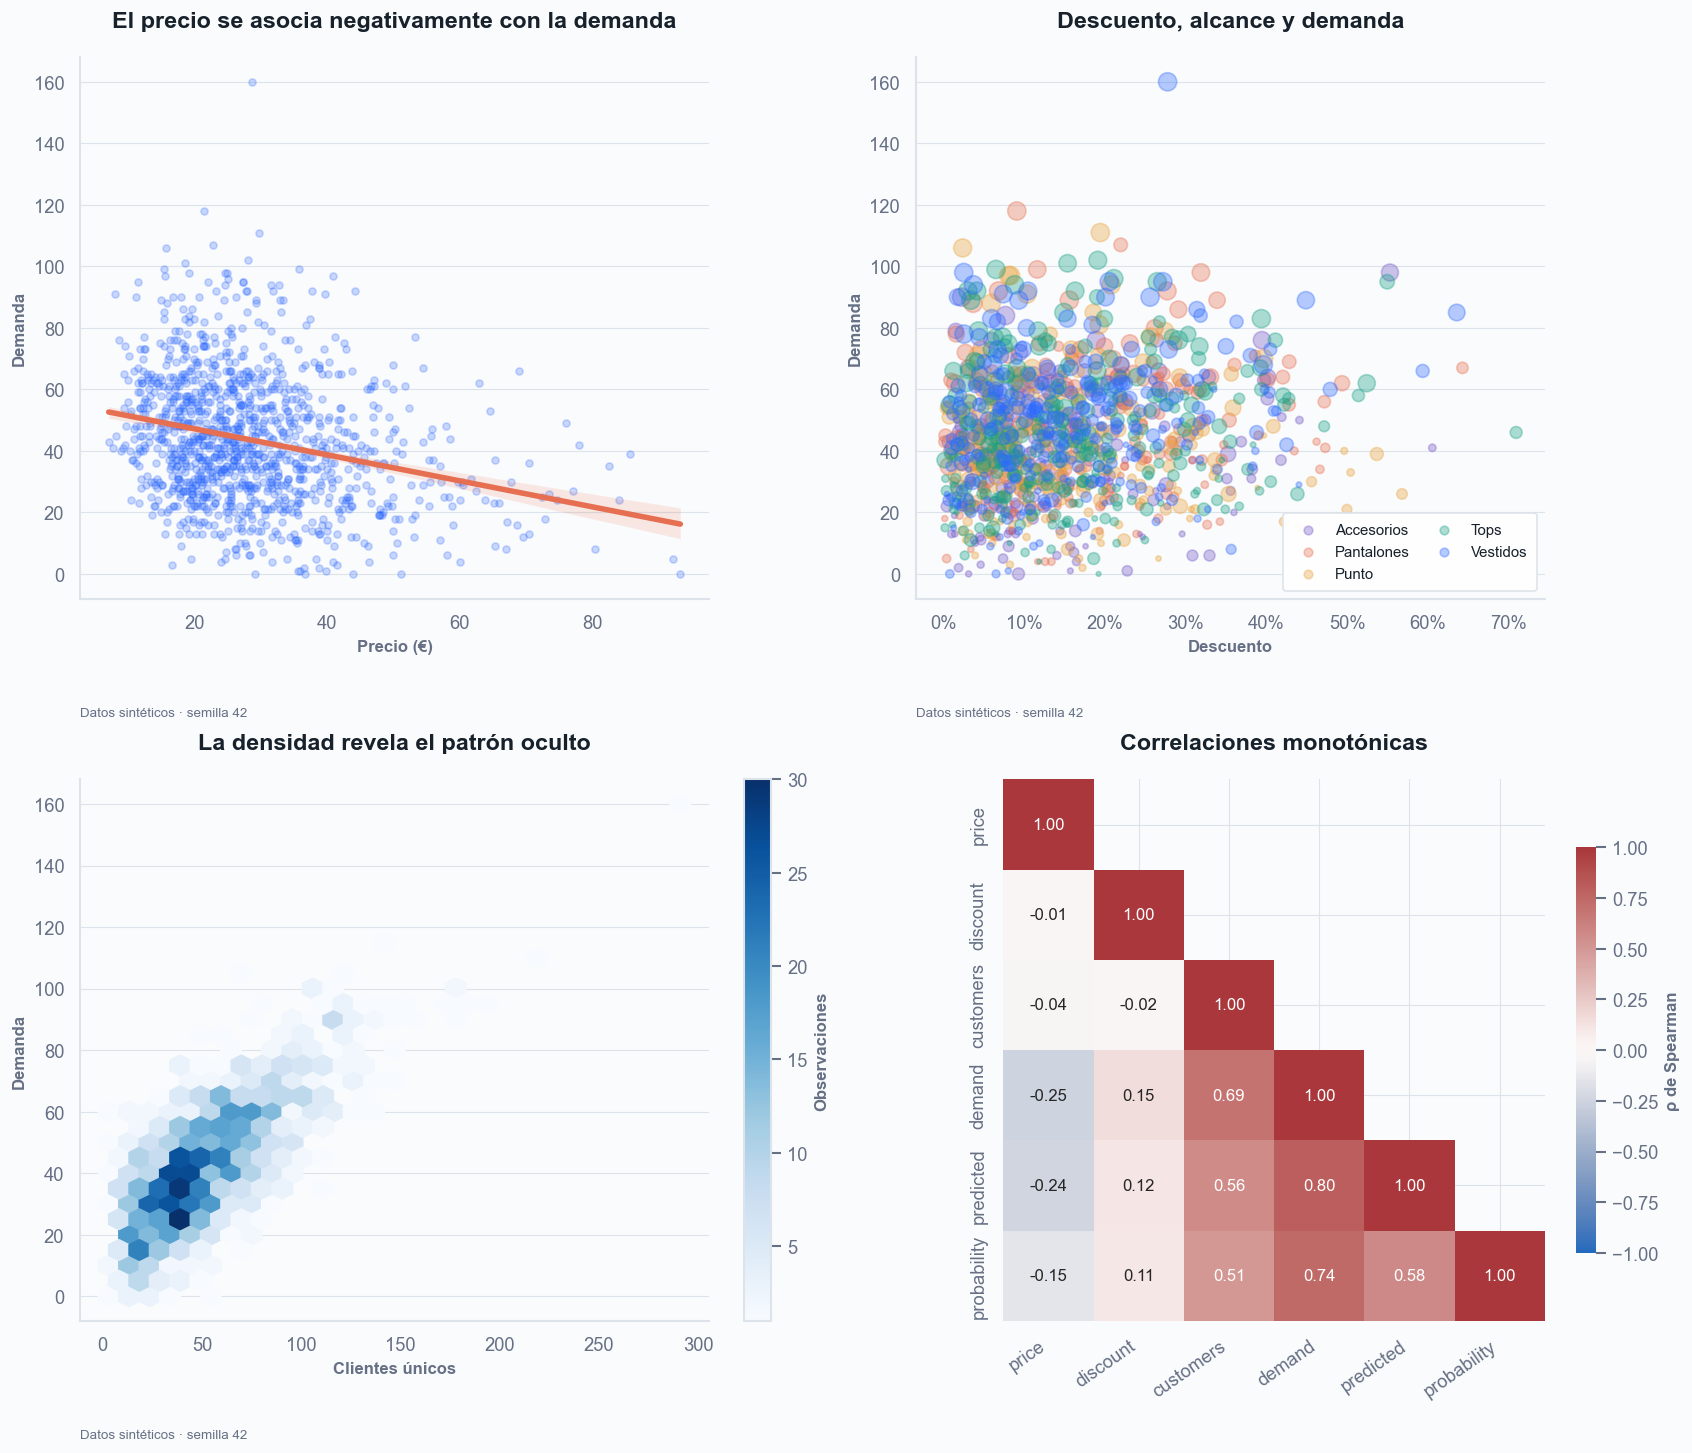

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12), layout='constrained')
sns.regplot(articles, x='price', y='demand', scatter_kws={'s':18,'alpha':.25,'color':BLUE}, line_kws={'color':CORAL}, ax=axes[0,0])
finish_plot(axes[0,0], 'El precio se asocia negativamente con la demanda', 'Regresión lineal con intervalo de confianza del 95 %', 'Precio (€)', 'Demanda')

cat_colors = dict(zip(categories, PALETTE))
for cat, group in articles.groupby('category'):
    axes[0,1].scatter(group.discount, group.demand, s=np.clip(group.customers, 8, 120), alpha=.35, color=cat_colors[cat], label=cat)
axes[0,1].xaxis.set_major_formatter(PercentFormatter(1)); axes[0,1].legend(markerscale=.65, ncol=2, loc='lower right')
finish_plot(axes[0,1], 'Descuento, alcance y demanda', 'Burbuja = clientes únicos; color = categoría', 'Descuento', 'Demanda')

hb = axes[1,0].hexbin(articles.customers, articles.demand, gridsize=28, mincnt=1, cmap='Blues')
fig.colorbar(hb, ax=axes[1,0], label='Observaciones')
finish_plot(axes[1,0], 'La densidad revela el patrón oculto', 'Hexbin para evitar sobreimpresión', 'Clientes únicos', 'Demanda')

corr_cols = ['price','discount','customers','demand','predicted','probability']
corr = articles[corr_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap='vlag', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', square=True, cbar_kws={'shrink':.75, 'label':'ρ de Spearman'}, ax=axes[1,1])
axes[1,1].set_title('Correlaciones monotónicas', loc='center', fontweight='bold', pad=18)
axes[1,1].set_xticklabels(axes[1,1].get_xticklabels(), rotation=35, ha='right')
plt.show()

## 6. Mapas de calor, calendario y Pareto

Los mapas de calor funcionan bien para matrices densas. El Pareto combina barras y acumulado para priorización; el segundo eje es aceptable aquí porque ambas escalas tienen una interpretación explícita y convencional.

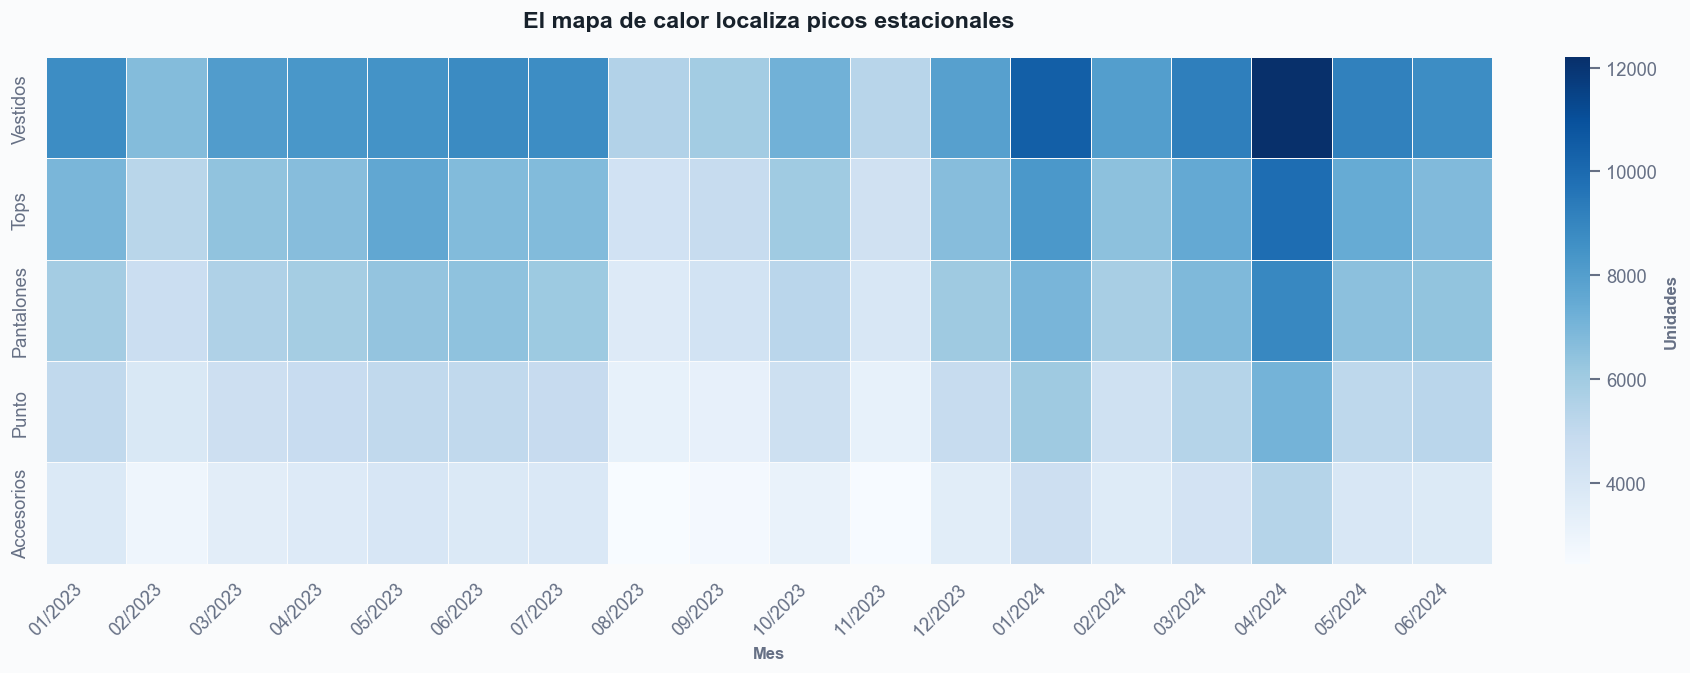

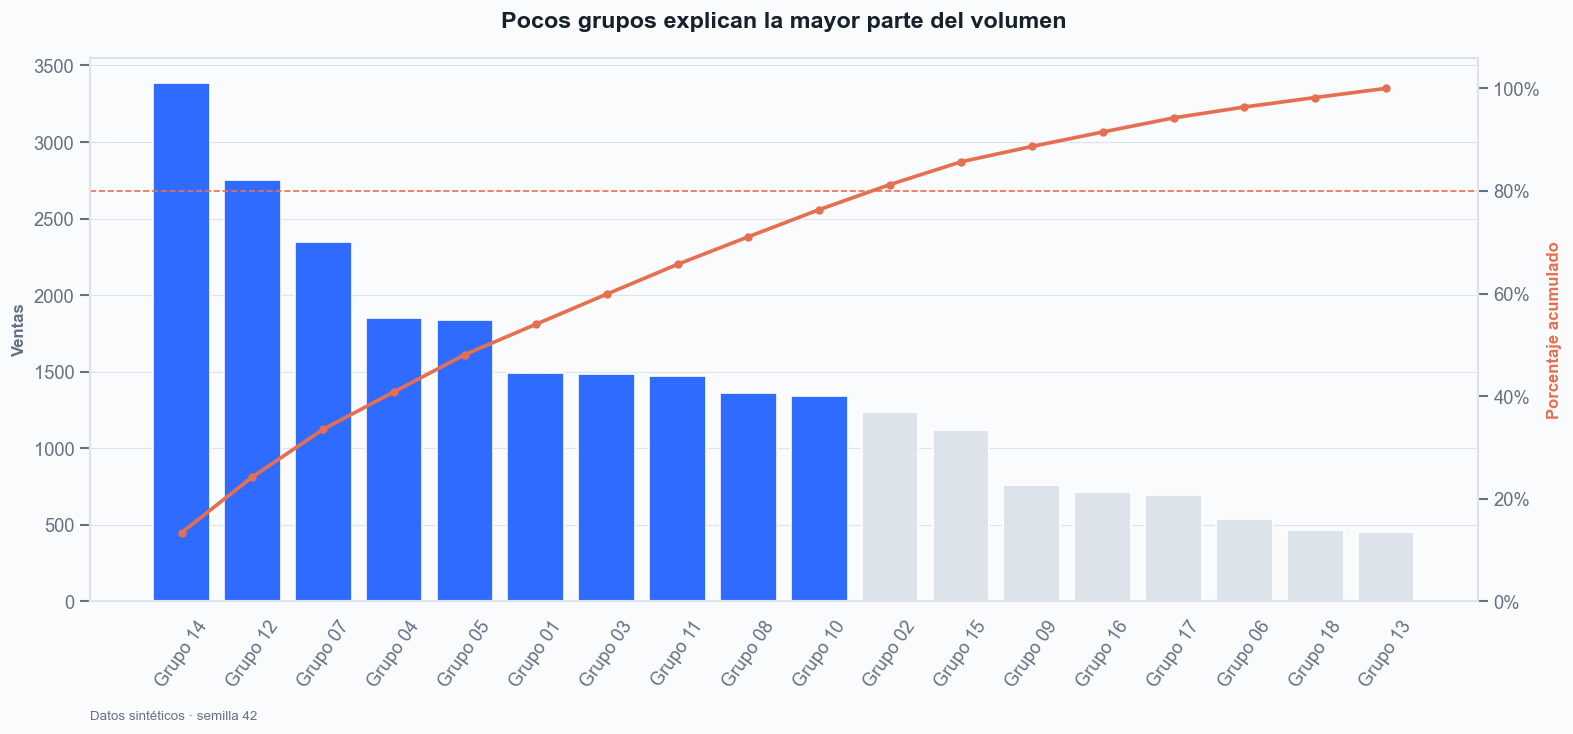

In [7]:
# Heatmap categoría × mes
month = weekly.assign(month=weekly.week.dt.to_period('M')).pivot_table(index='category', columns='month', values='sales', aggfunc='sum').loc[categories]
month.columns = [period.strftime('%m/%Y') for period in month.columns]
fig, ax = plt.subplots(figsize=(14, 5.5), layout='constrained')
sns.heatmap(month, cmap='Blues', linewidths=.5, linecolor=PAPER, cbar_kws={'label':'Unidades'}, ax=ax)
ax.set_title('El mapa de calor localiza picos estacionales', loc='center', fontweight='bold'); ax.set(xlabel='Mes', ylabel=None)
ax.xaxis.label.set_fontweight('bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right'); plt.show()

# Pareto de subcategorías sintéticas
items = pd.Series(rng.lognormal(7, .85, 18), index=[f'Grupo {i:02d}' for i in range(1,19)]).sort_values(ascending=False)
cum = items.cumsum()/items.sum()
fig, ax = plt.subplots(figsize=(13, 6), layout='constrained'); ax2 = ax.twinx()
ax.bar(items.index, items, color=[BLUE if c <= .8 else GRID for c in cum])
ax2.plot(items.index, cum, color=CORAL, marker='o', ms=4)
ax2.axhline(.8, color=CORAL, ls='--', lw=1); ax2.yaxis.set_major_formatter(PercentFormatter(1)); ax2.set_ylim(0,1.06)
ax.tick_params(axis='x', rotation=55); ax2.grid(False)
finish_plot(ax, 'Pocos grupos explican la mayor parte del volumen', 'Pareto: barras ordenadas y porcentaje acumulado', None, 'Ventas')
ax2.set_ylabel('Porcentaje acumulado', color=CORAL); plt.show()

## 7. Evaluación de regresión

No basta con una métrica agregada: contrastar observado vs. predicho, residuos, error por segmento y distribución del error. La diagonal representa predicción perfecta.

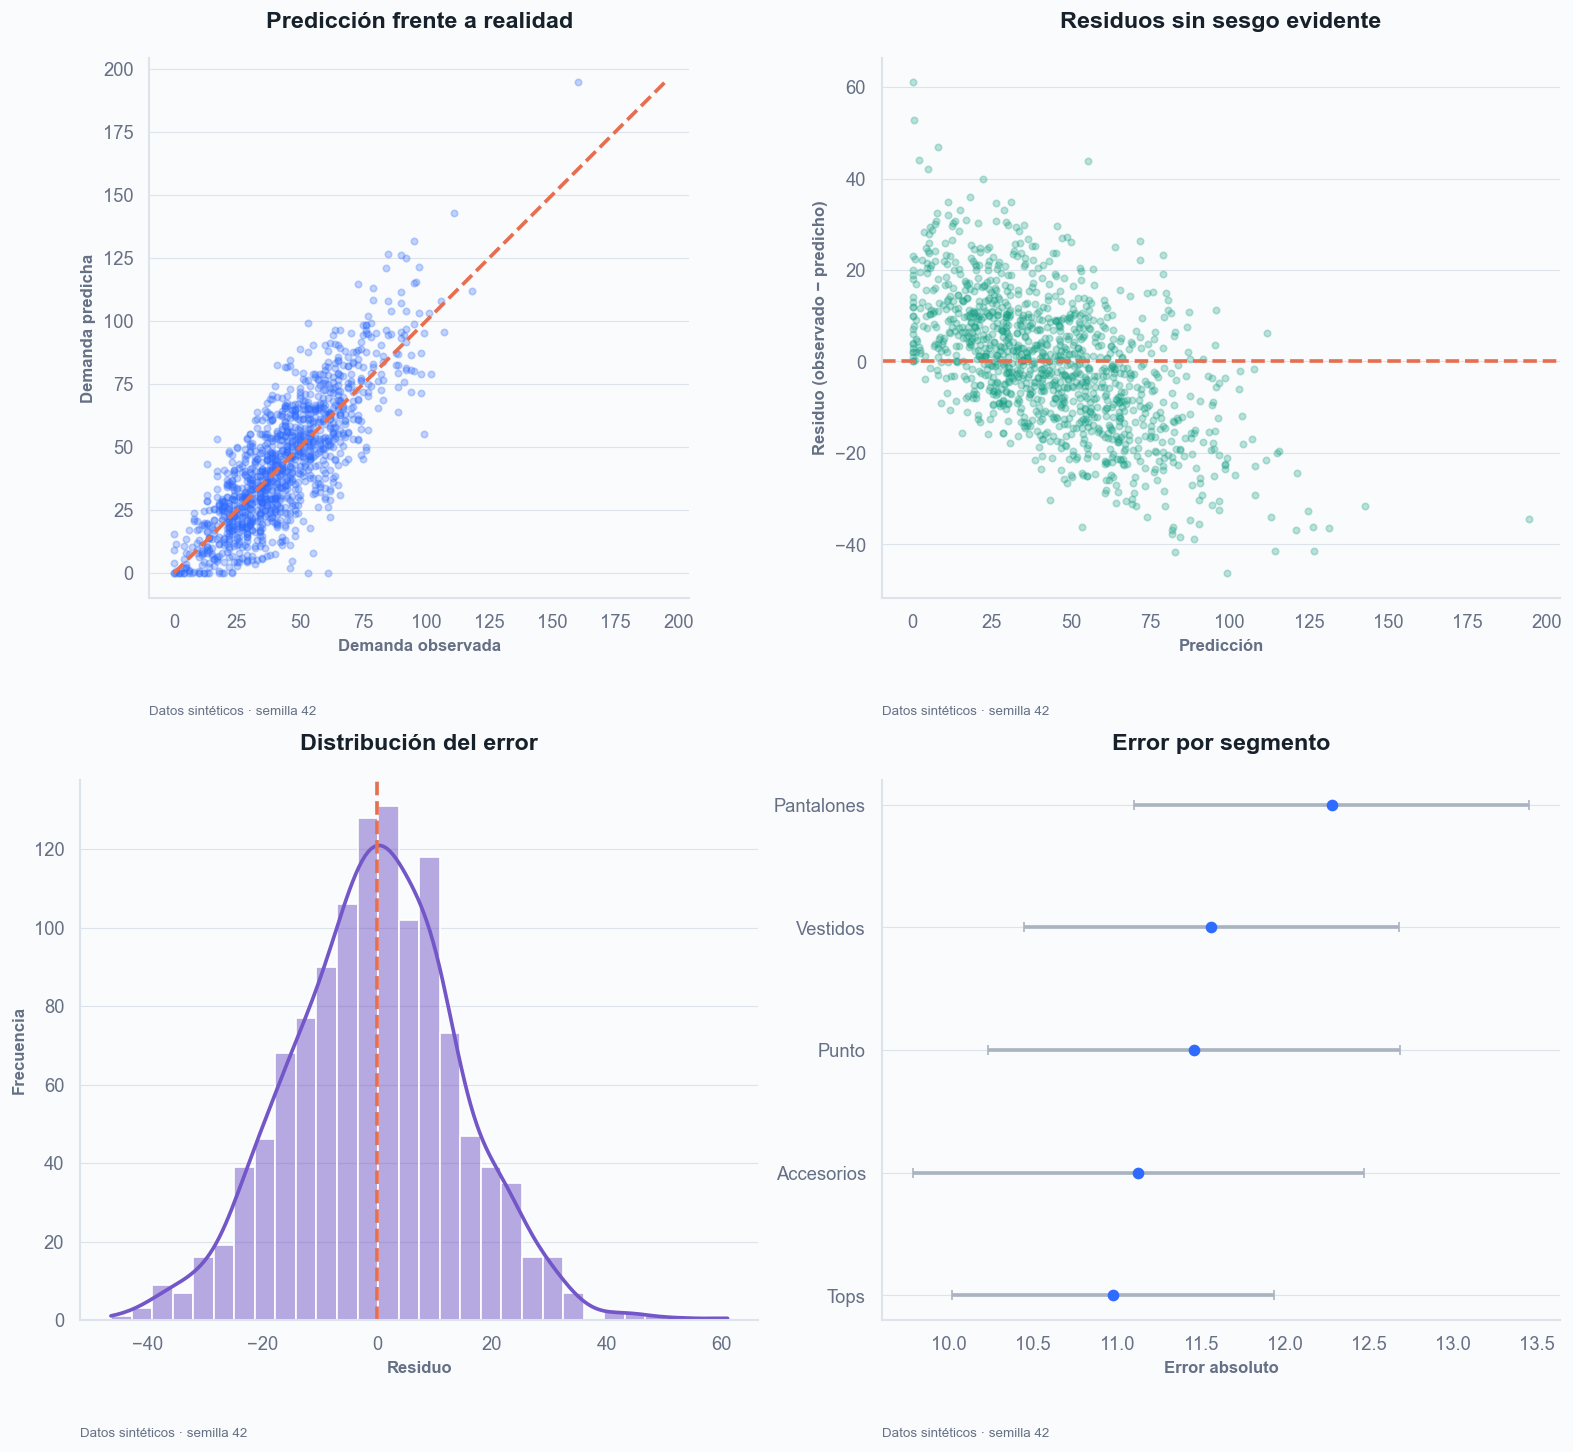

In [8]:
resid = articles.demand - articles.predicted
fig, axes = plt.subplots(2, 2, figsize=(13, 12), layout='constrained')
axes[0,0].scatter(articles.demand, articles.predicted, s=15, alpha=.28, color=BLUE)
limit = max(articles.demand.max(), articles.predicted.max()); axes[0,0].plot([0,limit],[0,limit], ls='--', color=CORAL)
axes[0,0].set_aspect('equal', adjustable='box'); finish_plot(axes[0,0], 'Predicción frente a realidad', 'La diagonal indica predicción perfecta', 'Demanda observada', 'Demanda predicha')

axes[0,1].scatter(articles.predicted, resid, s=15, alpha=.28, color=TEAL)
axes[0,1].axhline(0, color=CORAL, ls='--'); finish_plot(axes[0,1], 'Residuos sin sesgo evidente', 'Buscar curvatura, embudo y valores extremos', 'Predicción', 'Residuo (observado − predicho)')

sns.histplot(resid, bins='fd', kde=True, color=VIOLET, ax=axes[1,0])
axes[1,0].axvline(0, color=CORAL, ls='--'); finish_plot(axes[1,0], 'Distribución del error', 'Simetría alrededor de cero es deseable', 'Residuo', 'Frecuencia')

err = articles.assign(abs_error=resid.abs()).groupby('category').abs_error.agg(['mean','sem']).sort_values('mean')
axes[1,1].errorbar(err['mean'], err.index, xerr=1.96*err['sem'], fmt='o', color=BLUE, ecolor='#AAB4C0', capsize=3)
finish_plot(axes[1,1], 'Error por segmento', 'MAE medio e IC del 95 % aproximado', 'Error absoluto', None)
plt.show()

## 8. Evaluación de clasificación

Matriz de confusión normalizada para tipos de error; ROC para discriminación general; Precision–Recall cuando la clase positiva es infrecuente; calibración para comprobar si 0,8 significa aproximadamente 80 %.

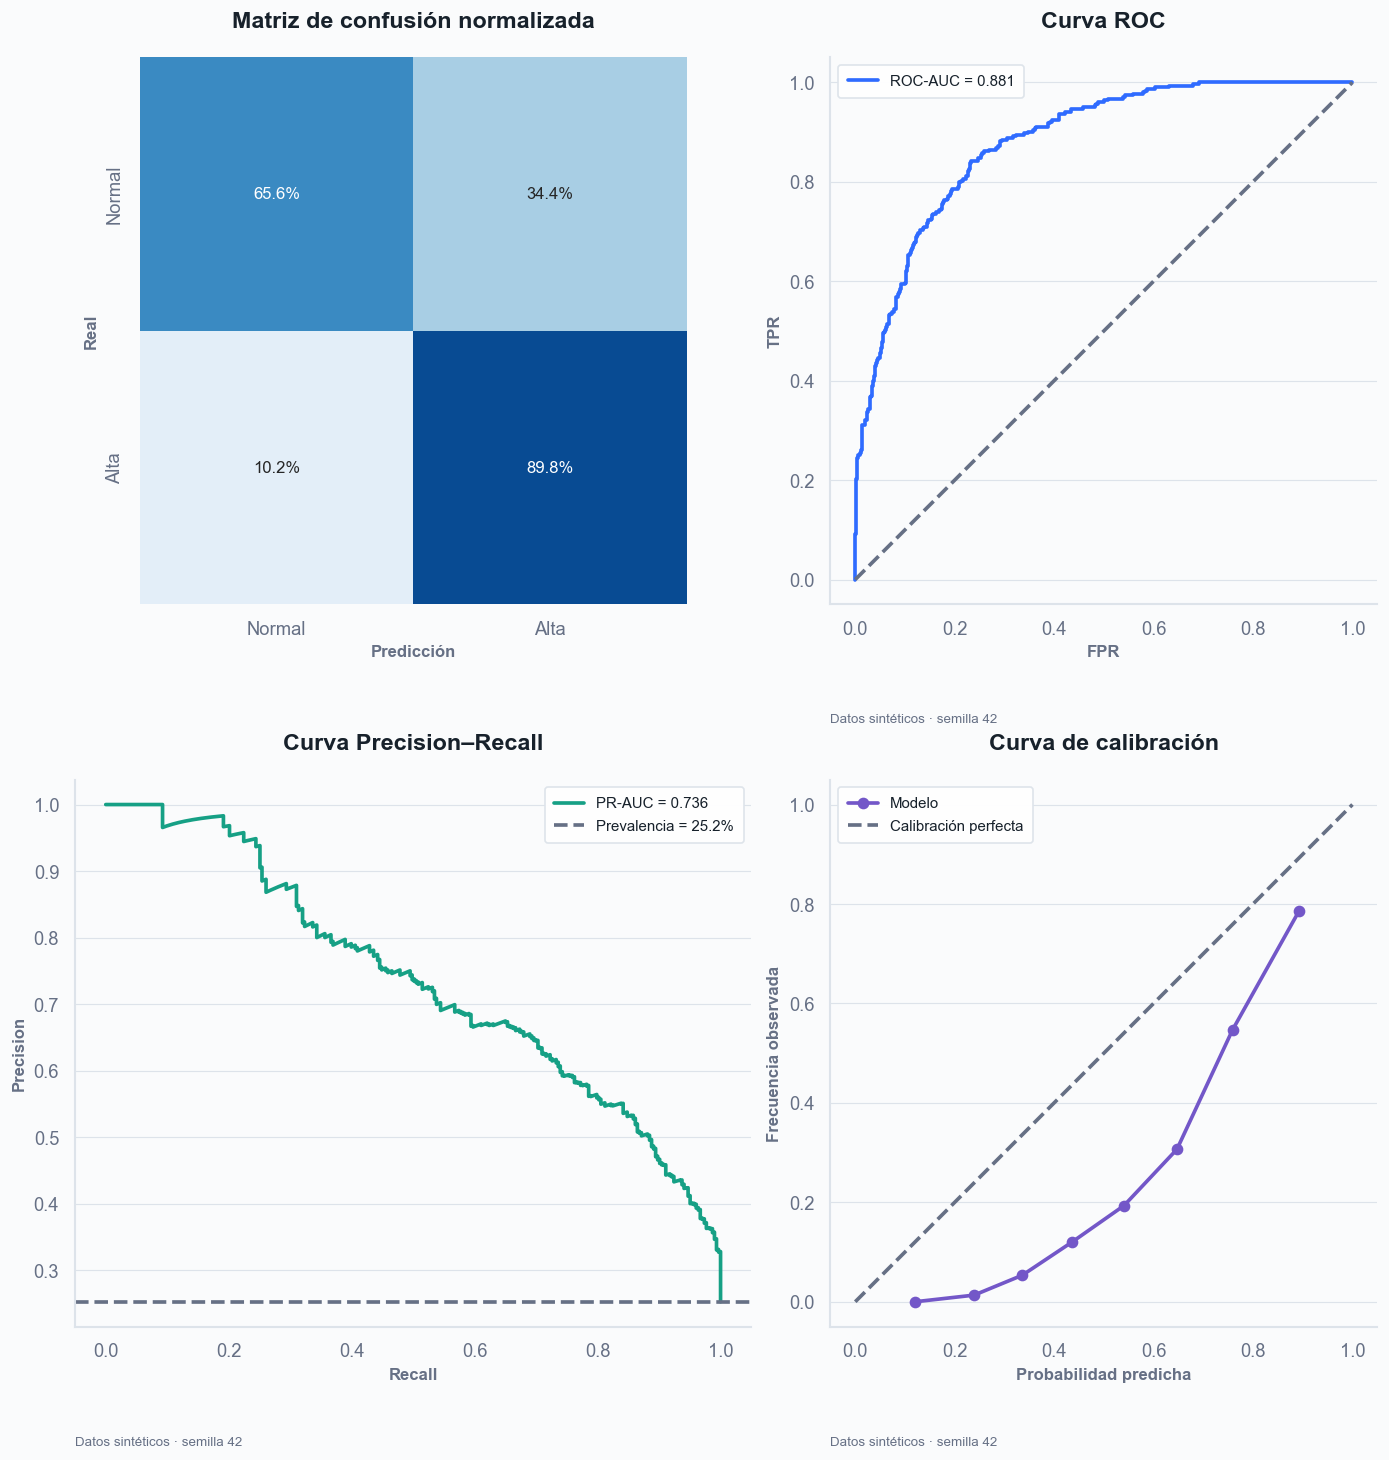

In [9]:
y = articles.high_demand.to_numpy(); p = articles.probability.to_numpy(); pred = (p >= .5).astype(int)
fpr, tpr, _ = roc_curve(y, p); precision, recall, _ = precision_recall_curve(y, p)
prob_true, prob_pred = calibration_curve(y, p, n_bins=8, strategy='quantile')
fig, axes = plt.subplots(2, 2, figsize=(12, 12), layout='constrained')
cm = confusion_matrix(y, pred, normalize='true')
sns.heatmap(cm, annot=True, fmt='.1%', cmap='Blues', vmin=0, vmax=1, square=True, cbar=False, ax=axes[0,0])
axes[0,0].set(xticklabels=['Normal','Alta'], yticklabels=['Normal','Alta'], xlabel='Predicción', ylabel='Real')
axes[0,0].set_title('Matriz de confusión normalizada', loc='center', fontweight='bold')
axes[0,0].xaxis.label.set_fontweight('bold'); axes[0,0].yaxis.label.set_fontweight('bold')

axes[0,1].plot(fpr, tpr, color=BLUE, label=f'ROC-AUC = {auc(fpr,tpr):.3f}'); axes[0,1].plot([0,1],[0,1], ls='--', color=MUTED)
axes[0,1].set_aspect('equal'); axes[0,1].legend(); finish_plot(axes[0,1], 'Curva ROC', 'Sensibilidad frente a tasa de falsos positivos', 'FPR', 'TPR')

baseline = y.mean(); axes[1,0].plot(recall, precision, color=TEAL, label=f'PR-AUC = {auc(recall[::-1],precision[::-1]):.3f}')
axes[1,0].axhline(baseline, ls='--', color=MUTED, label=f'Prevalencia = {baseline:.1%}'); axes[1,0].legend()
finish_plot(axes[1,0], 'Curva Precision–Recall', 'Más informativa con clases desequilibradas', 'Recall', 'Precision')

axes[1,1].plot(prob_pred, prob_true, marker='o', color=VIOLET, label='Modelo'); axes[1,1].plot([0,1],[0,1], ls='--', color=MUTED, label='Calibración perfecta')
axes[1,1].set_aspect('equal'); axes[1,1].legend(); finish_plot(axes[1,1], 'Curva de calibración', 'Probabilidad estimada frente a frecuencia observada', 'Probabilidad predicha', 'Frecuencia observada')
plt.show()

## 9. Comparación de modelos y explicabilidad

Comparar respecto a un baseline, no solo entre candidatos. Mostrar variabilidad entre particiones y separar rendimiento de coste. Para importancias, preferir permutación o SHAP frente a importancias impurity-based sin contexto.

/var/folders/_y/rfcjxtgs1c1_w1dp22mxqjp40000gn/T/ipykernel_36188/3812907520.py:4: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(folds, y='model', x='MAE', errorbar=('ci',95), join=False, color=BLUE, capsize=.15, ax=axes[0])


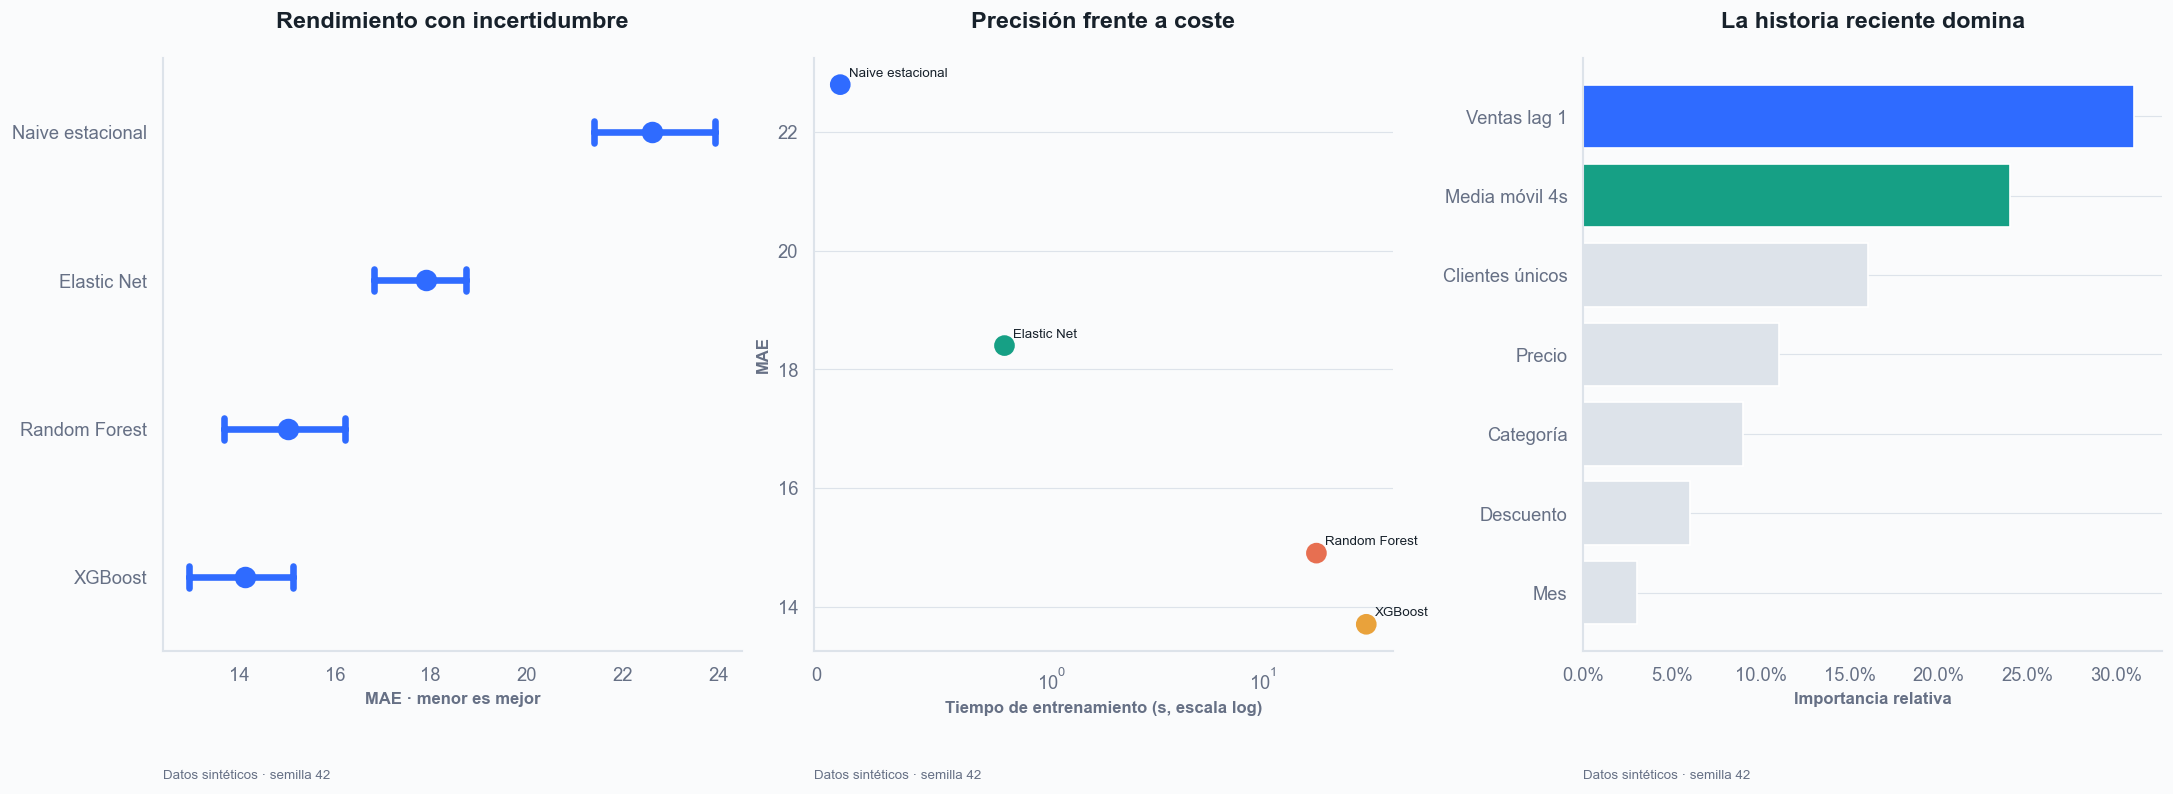

In [10]:
folds = pd.DataFrame([(m, f, mae+rng.normal(0,1.2)) for m, mae in model_metrics[['model','MAE']].itertuples(index=False) for f in range(1,7)], columns=['model','fold','MAE'])
features = pd.Series({'Ventas lag 1':.31, 'Media móvil 4s':.24, 'Clientes únicos':.16, 'Precio':.11, 'Categoría':.09, 'Descuento':.06, 'Mes':.03}).sort_values()
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5), layout='constrained')
sns.pointplot(folds, y='model', x='MAE', errorbar=('ci',95), join=False, color=BLUE, capsize=.15, ax=axes[0])
finish_plot(axes[0], 'Rendimiento con incertidumbre', 'Media e IC 95 % entre particiones temporales', 'MAE · menor es mejor', None)

axes[1].scatter(model_metrics.train_s, model_metrics.MAE, s=130, c=PALETTE[:4])
for row in model_metrics.itertuples(): axes[1].annotate(row.model, (row.train_s,row.MAE), xytext=(5,5), textcoords='offset points', fontsize=8)
axes[1].set_xscale('symlog', linthresh=1); finish_plot(axes[1], 'Precisión frente a coste', 'Frontera de decisión rendimiento–tiempo', 'Tiempo de entrenamiento (s, escala log)', 'MAE')

axes[2].barh(features.index, features.values, color=[GRID]*5+[TEAL,BLUE])
axes[2].xaxis.set_major_formatter(PercentFormatter(1)); finish_plot(axes[2], 'La historia reciente domina', 'Importancia por permutación normalizada', 'Importancia relativa', None)
plt.show()

## 10. Clustering y reducción dimensional

PCA permite proyectar, no demostrar separación. Añadir varianza explicada, diagnóstico de silhouette y perfiles de clúster. El dendrograma es útil para muestras pequeñas.

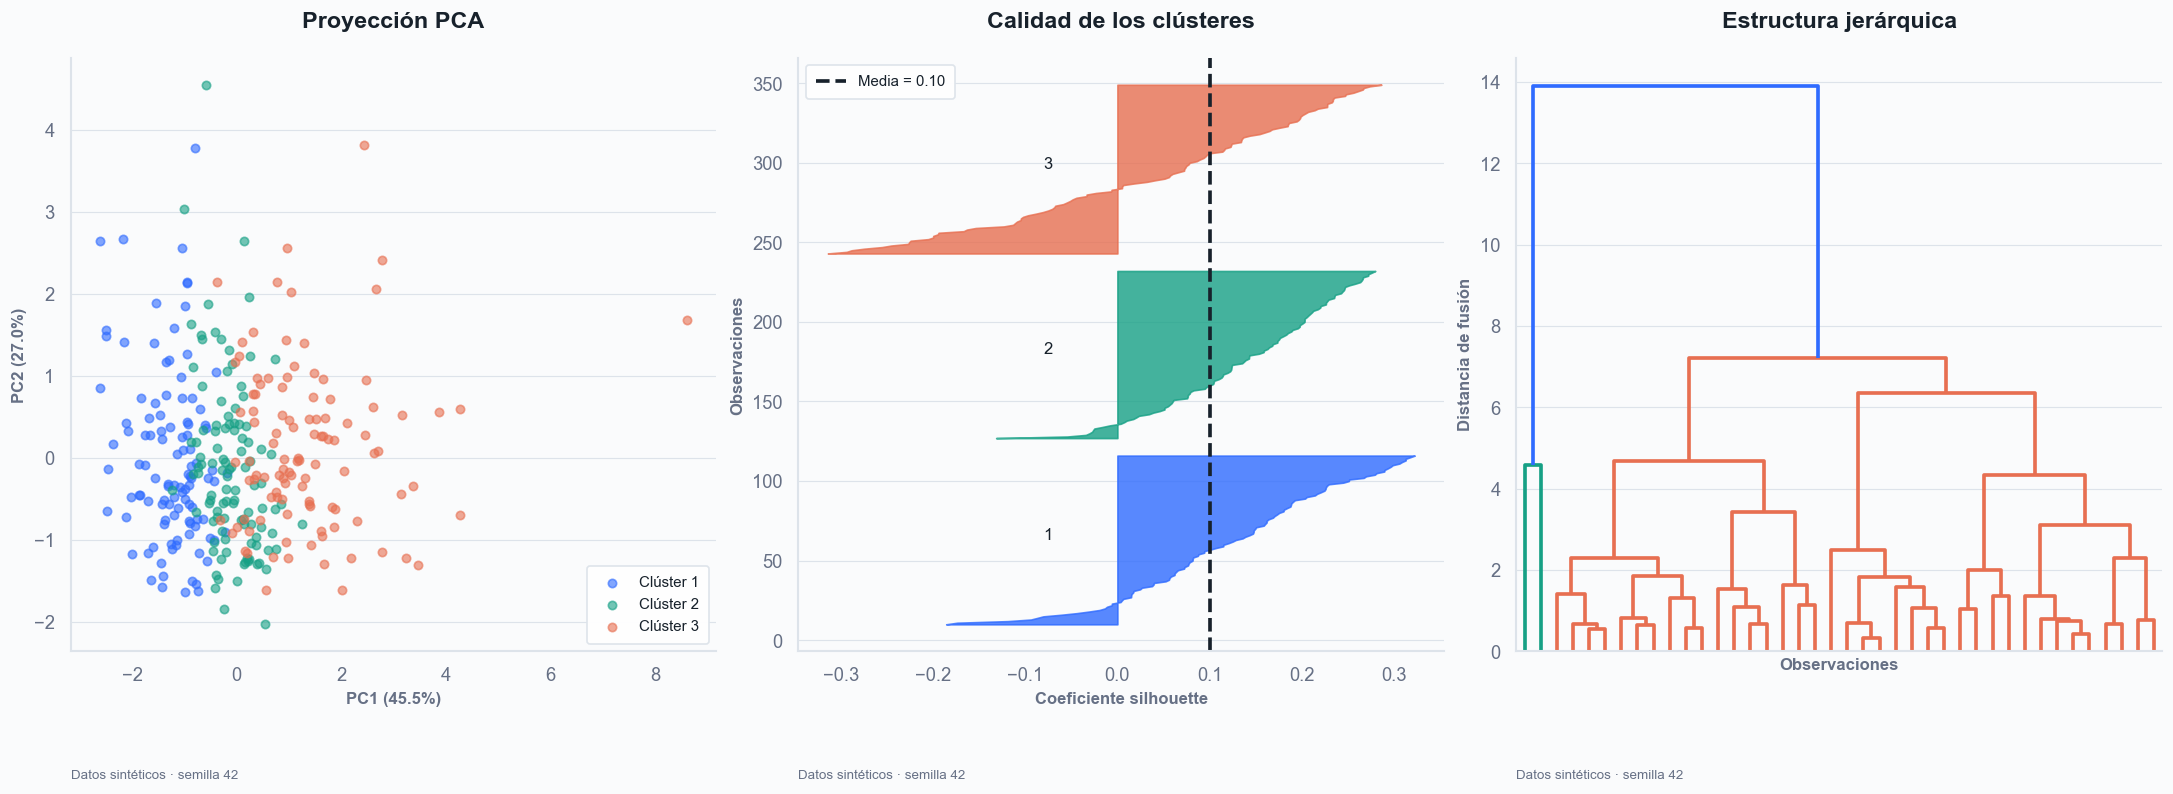

In [11]:
cluster_data = articles[['price','discount','customers','demand']].sample(320, random_state=SEED)
X = StandardScaler().fit_transform(cluster_data)
# Etiquetas ilustrativas basadas en cuantiles; sustituir por las del modelo real.
labels = pd.qcut(cluster_data.demand.rank(method='first'), 3, labels=[0,1,2]).astype(int).to_numpy()
pca = PCA(2, random_state=SEED).fit(X); Z = pca.transform(X)
sil = silhouette_samples(X, labels)
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5), layout='constrained')
for k, color in zip(range(3), [BLUE,TEAL,CORAL]):
    axes[0].scatter(Z[labels==k,0], Z[labels==k,1], s=25, alpha=.6, color=color, label=f'Clúster {k+1}')
axes[0].legend(loc='lower right'); finish_plot(axes[0], 'Proyección PCA', f'PC1 + PC2 explican {pca.explained_variance_ratio_.sum():.1%} de la varianza', f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')

y_lower = 10
for k, color in zip(range(3), [BLUE,TEAL,CORAL]):
    vals = np.sort(sil[labels==k]); y_upper=y_lower+len(vals)
    axes[1].fill_betweenx(np.arange(y_lower,y_upper), 0, vals, color=color, alpha=.8); axes[1].text(-.08,(y_lower+y_upper)/2,str(k+1)); y_lower=y_upper+10
axes[1].axvline(sil.mean(), color=INK, ls='--', label=f'Media = {sil.mean():.2f}'); axes[1].legend()
finish_plot(axes[1], 'Calidad de los clústeres', 'Silhouette por observación y media global', 'Coeficiente silhouette', 'Observaciones')

sample_X = X[:40]; dendrogram(linkage(sample_X, method='ward'), no_labels=True, color_threshold=None, above_threshold_color=BLUE, ax=axes[2])
finish_plot(axes[2], 'Estructura jerárquica', 'Dendrograma Ward de una muestra (n = 40)', 'Observaciones', 'Distancia de fusión')
plt.show()

## 11. Entrenamiento de Deep Learning

Curvas de aprendizaje con el mismo eje para train/validation; marcar el mejor epoch y, si existen varias semillas, mostrar media ± desviación. Útil también para el repositorio `fashion-vision-dl`.

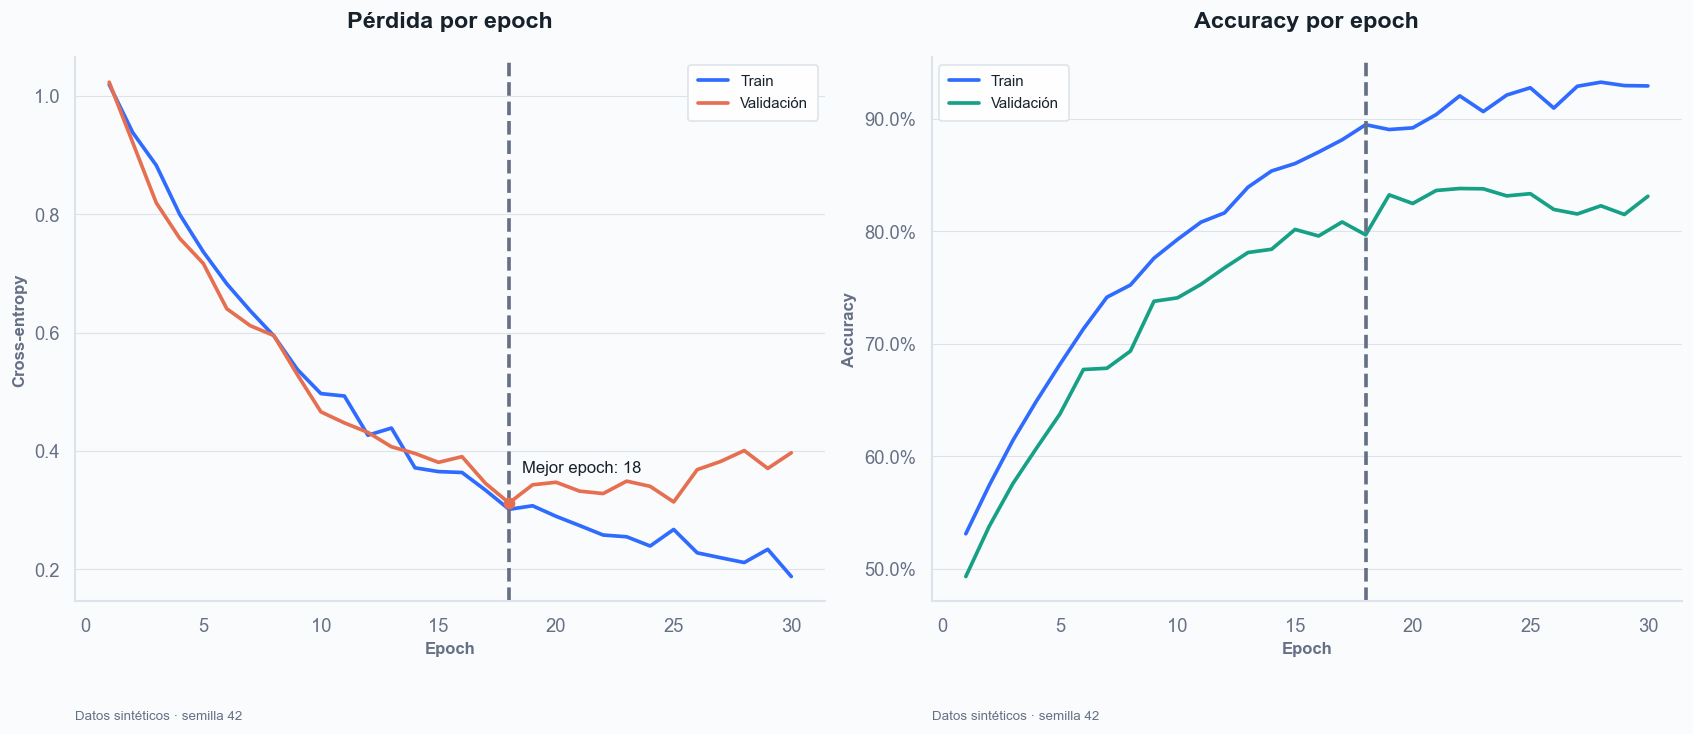

In [12]:
epoch = np.arange(1,31)
train_loss = .95*np.exp(-epoch/10)+.16+rng.normal(0,.012,30)
val_loss = .88*np.exp(-epoch/8)+.24+np.maximum(epoch-19,0)*.012+rng.normal(0,.018,30)
train_acc = .48+.47*(1-np.exp(-epoch/9))+rng.normal(0,.006,30)
val_acc = .45+.41*(1-np.exp(-epoch/8))-np.maximum(epoch-22,0)*.004+rng.normal(0,.009,30)
best = np.argmin(val_loss)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
axes[0].plot(epoch, train_loss, color=BLUE, label='Train'); axes[0].plot(epoch,val_loss,color=CORAL,label='Validación')
axes[0].axvline(epoch[best], color=MUTED, ls='--'); axes[0].scatter(epoch[best],val_loss[best],color=CORAL,zorder=3)
axes[0].annotate(f'Mejor epoch: {epoch[best]}', (epoch[best],val_loss[best]), xytext=(8,18), textcoords='offset points'); axes[0].legend()
finish_plot(axes[0], 'Pérdida por epoch', 'El repunte de validación señala sobreajuste', 'Epoch', 'Cross-entropy')
axes[1].plot(epoch,train_acc,color=BLUE,label='Train'); axes[1].plot(epoch,val_acc,color=TEAL,label='Validación'); axes[1].axvline(epoch[best],color=MUTED,ls='--'); axes[1].legend()
axes[1].yaxis.set_major_formatter(PercentFormatter(1)); finish_plot(axes[1], 'Accuracy por epoch', 'Misma partición y punto de early stopping', 'Epoch', 'Accuracy')
plt.show()

## 12. Contribuciones al cambio

Las barras divergentes muestran de forma directa qué factores aumentan o reducen la demanda. Las contribuciones deben ser aditivas y estar documentadas; su suma coincide con el cambio entre el valor inicial y el final.

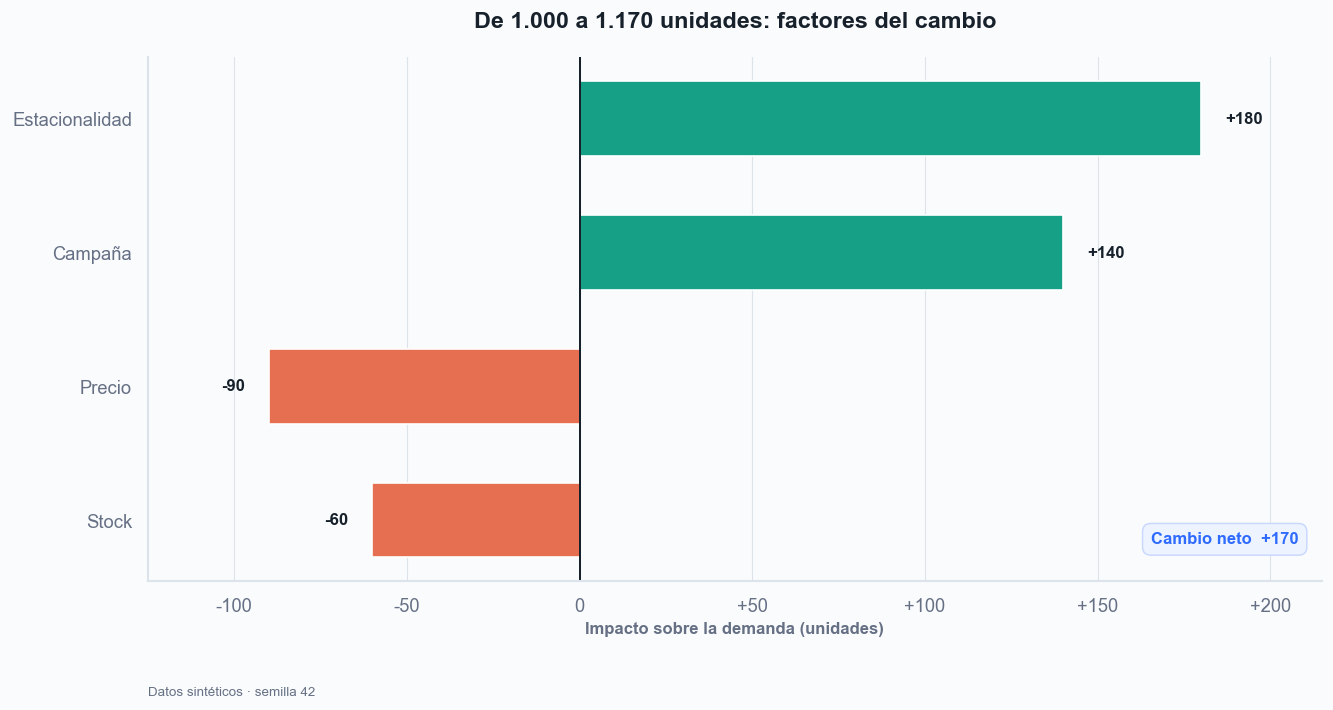

In [13]:
factors = pd.Series({'Estacionalidad': 180, 'Campaña': 140, 'Precio': -90, 'Stock': -60})
base = 1_000
final = base + factors.sum()
colors = [TEAL if value > 0 else CORAL for value in factors]

fig, ax = plt.subplots(figsize=(11, 5.8), layout='constrained')
bars = ax.barh(factors.index, factors.values, color=colors, height=.56)
ax.axvline(0, color=INK, lw=1.2)
ax.invert_yaxis()
for bar, value in zip(bars, factors):
    x = value + (7 if value > 0 else -7)
    ax.text(x, bar.get_y()+bar.get_height()/2, f'{value:+.0f}',
            va='center', ha='left' if value > 0 else 'right',
            color=INK, fontsize=10, fontweight='bold')
ax.set_xlim(-125, 215)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: '0' if x == 0 else f'{x:+.0f}'))
finish_plot(ax, f'De {base:,.0f} a {final:,.0f} unidades: factores del cambio'.replace(',', '.'),
            None, 'Impacto sobre la demanda (unidades)', None)
ax.grid(axis='x', visible=True, color=GRID, lw=.7)
ax.grid(axis='y', visible=False)
ax.text(.98, .08, f'Cambio neto  {factors.sum():+.0f}', transform=ax.transAxes,
        ha='right', va='center', fontsize=10, fontweight='bold', color=BLUE,
        bbox={'boxstyle':'round,pad=.5', 'facecolor':'#EEF4FF',
              'edgecolor':'#C9D8FF', 'linewidth':.9})
plt.show()

## 13. Qué gráfico usar

| Pregunta | Opción principal | Complemento riguroso | Evitar |
|---|---|---|---|
| ¿Cómo cambia en el tiempo? | Línea | Banda de incertidumbre; paneles múltiples equilibrados | Eje dual, demasiadas líneas, fechas insuficientes |
| ¿Qué categoría es mayor? | Barras ordenadas / lollipop | IC si es una estimación | Tarta con muchas categorías |
| ¿Cómo se distribuye? | Histograma + KDE / ECDF | Intervalos robustos y ridgelines | Solo media, nubes de puntos saturadas |
| ¿Hay relación? | Scatter / hexbin | Regresión + IC | Inferir causalidad |
| ¿Cómo se compone? | Barra 100 % / área apilada | Tabla de porcentajes | 3D |
| ¿Dónde están los patrones? | Heatmap | Etiquetas selectivas | Rainbow colormap |
| ¿Predice bien regresión? | Real vs. predicho + residuos | Error por segmento | Solo R² |
| ¿Clasifica bien? | Confusión + PR/ROC + calibración | Umbral y prevalencia | Solo accuracy |
| ¿Se separan los clústeres? | PCA + silhouette + perfiles | Estabilidad entre semillas | PCA como prueba |
| ¿Cómo entrenó la red? | Learning curves | Variación entre semillas | Solo mejor epoch |
| ¿Qué explica un cambio? | Barras divergentes de contribución | Base, resultado y cambio neto | Waterfall difícil de reconstruir |

### Lista de control antes de publicar

- Un único título centrado y en negrita; la explicación metodológica va en el texto del notebook.
- Nombres de ejes en negrita; ticks, valores, fechas, anotaciones y leyendas en peso normal.
- Ejes, unidades, población, `n`, fuente y transformación claramente indicados; una sola fuente por figura.
- Fechas siempre en formato español: `dd/mm/aaaa` o `mm/aaaa`; todos los paneles temporales muestran su eje X con referencias suficientes.
- En paneles múltiples, distribuir los gráficos de forma equilibrada: ninguna fila debe quedar con un único panel.
- Leyendas dentro de un contenedor blanco, con borde fino y esquinas redondeadas.
- Barras desde cero; escalas logarítmicas declaradas; misma escala al comparar paneles.
- Intervalos o variabilidad cuando se muestran estimaciones.
- Paleta apta para daltonismo; el color de énfasis se reserva al hallazgo.
- Redondeo acorde con la precisión real; no añadir decimales ficticios.
- Exportar en SVG para informe y PNG a 240–300 dpi para presentaciones.
- Evitar 3D, tartas fragmentadas, arcoíris, exceso de etiquetas y decoración sin función.